In [1]:
from pathlib import Path

PROJECT_ROOT = Path("/content/twincheck")

folders = [
    "data/raw/verite",
    "data/raw/genimage",
    "data/processed/vision",
    "data/copies/vision",
    "features/vision",
    "models/vision",
    "results/vision",
    "src/vision",
    "notes"
]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("TwinCheck vision folders created successfully!")
print("Project location:", PROJECT_ROOT)

TwinCheck vision folders created successfully!
Project location: /content/twincheck


In [2]:
!pip install pandas pillow tqdm requests

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

# Main project directory in Google Drive
PROJECT_ROOT = Path("/content/drive/MyDrive/twincheck")

# Create required directories
DIRECTORIES = [
    "data/raw/verite",
    "data/raw/genimage",
    "data/processed/vision",
    "data/copies/vision",
    "features/vision",
    "models/vision",
    "results/vision",
    "src/vision",
    "notes"
]

for directory in DIRECTORIES:
    (PROJECT_ROOT / directory).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project workspace created successfully!")
print(f"Project location: {PROJECT_ROOT}")

Project workspace created successfully!
Project location: /content/drive/MyDrive/twincheck


In [5]:
for directory in sorted(PROJECT_ROOT.rglob("*")):
    if directory.is_dir():
        print(directory.relative_to(PROJECT_ROOT))

data
data/copies
data/copies/vision
data/processed
data/processed/vision
data/raw
data/raw/genimage
data/raw/verite
features
features/vision
models
models/vision
notes
results
results/vision
src
src/vision


VERITE

In [6]:
import subprocess
from pathlib import Path

VENDOR_DIR = Path("/content/twincheck_external")
VENDOR_DIR.mkdir(parents=True, exist_ok=True)

VERITE_REPO = (
    "https://github.com/stevejpapad/"
    "image-text-verification.git"
)

result = subprocess.run(
    [
        "git", "clone", "--depth", "1",
        VERITE_REPO,
        str(VENDOR_DIR / "verite_reference")
    ],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("VERITE repository cloned successfully!")
else:
    print(result.stderr)

VERITE repository cloned successfully!


In [7]:
VERITE_REFERENCE = VENDOR_DIR / "verite_reference"

for item in sorted(VERITE_REFERENCE.iterdir()):
    print(item.name)

.git
LICENSE
README.md
VERITE
experiment.py
extract_features.py
main.py
model.py
prepare_datasets.py
requirements.txt
utils.py


RED-DOT

In [8]:
RED_DOT_REPO = (
    "https://github.com/stevejpapad/"
    "relevant-evidence-detection.git"
)

result = subprocess.run(
    [
        "git", "clone", "--depth", "1",
        RED_DOT_REPO,
        str(VENDOR_DIR / "red_dot_reference")
    ],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("RED-DOT repository cloned successfully!")
else:
    print(result.stderr)

RED-DOT repository cloned successfully!


In [9]:
RED_DOT_DIR = VENDOR_DIR / "red_dot_reference"

VERITE_DATA_DIR = RED_DOT_DIR / "data" / "VERITE"

print("VERITE directory exists:", VERITE_DATA_DIR.exists())

if VERITE_DATA_DIR.exists():
    for item in sorted(VERITE_DATA_DIR.rglob("*")):
        if item.is_file():
            print(item.relative_to(RED_DOT_DIR))

VERITE directory exists: True
data/VERITE/VERITE.csv
data/VERITE/VERITE_articles.csv
data/VERITE/VERITE_clip_image_embeddings_ViTB32.npy
data/VERITE/VERITE_clip_text_embeddings_ViTB32.npy
data/VERITE/VERITE_external_clip_image_embeddings_ViTB32.npy
data/VERITE/VERITE_external_clip_text_embeddings_ViTB32.npy
data/VERITE/VERITE_external_image_ids_ViTB32.npy
data/VERITE/VERITE_external_text_ids_ViTB32.npy
data/VERITE/VERITE_image_ids_ViTB32.npy
data/VERITE/VERITE_item_ids_ViTB32.npy
data/VERITE/VERITE_ranked_evidence_clip_ViTB32.csv
data/VERITE/VERITE_text_ids_ViTB32.npy
data/VERITE/VERITE_with_evidence.csv
data/VERITE/external_evidence/false_direct_0.json
data/VERITE/external_evidence/false_direct_1.json
data/VERITE/external_evidence/false_direct_10.json
data/VERITE/external_evidence/false_direct_100.json
data/VERITE/external_evidence/false_direct_101.json
data/VERITE/external_evidence/false_direct_102.json
data/VERITE/external_evidence/false_direct_103.json
data/VERITE/external_evidence

In [10]:
import pandas as pd
import numpy as np
import json
import os
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
VERITE_DATA_DIR = (
    Path("/content/twincheck_external")
    / "red_dot_reference"
    / "data"
    / "VERITE"
)

verite_csv = pd.read_csv(
    VERITE_DATA_DIR / "VERITE.csv"
)

articles_csv = pd.read_csv(
    VERITE_DATA_DIR / "VERITE_articles.csv"
)

evidence_csv = pd.read_csv(
    VERITE_DATA_DIR / "VERITE_with_evidence.csv"
)

print("VERITE shape:", verite_csv.shape)
print("Articles shape:", articles_csv.shape)
print("Evidence shape:", evidence_csv.shape)

VERITE shape: (1001, 4)
Articles shape: (338, 8)
Evidence shape: (1001, 8)


In [12]:
print("VERITE COLUMNS:")
print(verite_csv.columns.tolist())

print("\nARTICLE COLUMNS:")
print(articles_csv.columns.tolist())

print("\nEVIDENCE COLUMNS:")
print(evidence_csv.columns.tolist())

VERITE COLUMNS:
['Unnamed: 0', 'caption', 'image_path', 'label']

ARTICLE COLUMNS:
['Unnamed: 0', 'id', 'true_url', 'false_caption', 'true_caption', 'false_url', 'query', 'snopes_url']

EVIDENCE COLUMNS:
['Unnamed: 0', 'caption', 'image_path', 'captions', 'len_text_info', 'images_paths', 'num_images', 'label']


In [13]:
print("VERITE SAMPLE:")
display(verite_csv.head(5))

print("ARTICLE SAMPLE:")
display(articles_csv.head(5))

print("EVIDENCE SAMPLE:")
display(evidence_csv.head(5))

VERITE SAMPLE:


,Unnamed: 0,caption,image_path,label
0,0,Photograph shows a family that was taken away ...,images/true_0.jpg,true
1,1,Photograph shows Chinese officials in white pr...,images/true_0.jpg,miscaptioned
2,2,Photograph shows a family that was taken away ...,images/false_0.jpg,out-of-context
3,3,Image shows electric scooters abandoned due to...,images/true_1.jpg,true
4,4,Image shows electric green scooters that have ...,images/true_1.jpg,miscaptioned


ARTICLE SAMPLE:


,Unnamed: 0,id,true_url,false_caption,true_caption,false_url,query,snopes_url
0,0,0,https://mediaproxy.snopes.com/width/600/https:...,Photograph shows Chinese officials in white pr...,Photograph shows a family that was taken away ...,https://static.dw.com/image/63908432_604.jpg,shenzhen police arresting during covid,https://www.snopes.com/fact-check/china-covid-...
1,1,1,https://ic.pics.livejournal.com/elesika73/5218...,Image shows electric green scooters that have ...,Image shows electric scooters abandoned due to...,https://miro.medium.com/max/1400/0*-wsuYdEl66h...,scooters in landfield,https://www.snopes.com/fact-check/electric-sco...
2,2,2,https://mediaproxy.snopes.com/width/1200/https...,Image shows Balenciaga stylist Lotta Volkova h...,Image shows unnamed runway model showcasing de...,https://images.squarespace-cdn.com/content/5b5...,Sheguang Hu's collection,https://www.snopes.com/fact-check/balenciaga-s...
3,3,3,https://mediaproxy.snopes.com/width/1200/https...,"3D model accurately depicting what Joseph, hus...",A sketchfab 3D rendering of the actor Andre th...,https://www.si.com/.image/t_share/MTkzMzI3MTk1...,Andre the Giant,https://www.snopes.com/fact-check/3d-model-jos...
4,4,4,https://www.businessgeegz.com/wp-content/uploa...,Image shows hundreds of white electric cars th...,Image shows abandoned white cars in China that...,https://www.riwasaki.com/img-get/I0000ljk5V2Q2...,white cars parked,https://www.snopes.com/fact-check/electric-car...


EVIDENCE SAMPLE:


,Unnamed: 0,caption,image_path,captions,len_text_info,images_paths,num_images,label
0,0,Photograph shows a family that was taken away ...,images/true_0.jpg,['Video Shows Police in China Enforcing Quaran...,2,['/fssd7/user-data/stefpapad/MISINFO/FIGMENTS/...,8,true
1,1,Photograph shows Chinese officials in white pr...,images/true_0.jpg,['Video Shows Police in China Enforcing Quaran...,2,['/fssd7/user-data/stefpapad/MISINFO/FIGMENTS/...,17,miscaptioned
2,2,Photograph shows a family that was taken away ...,images/false_0.jpg,['Nationwide protests in China call for easing...,3,['/fssd7/user-data/stefpapad/MISINFO/FIGMENTS/...,8,out-of-context
3,3,Image shows electric scooters abandoned due to...,images/true_1.jpg,[],0,['/fssd7/user-data/stefpapad/MISINFO/FIGMENTS/...,1,true
4,4,Image shows electric green scooters that have ...,images/true_1.jpg,[],0,['/fssd7/user-data/stefpapad/MISINFO/FIGMENTS/...,28,miscaptioned


In [14]:
print("VERITE DATASET INFORMATION")
print("-" * 40)

print("Total records:", len(verite_csv))

print("\nMissing values:")
print(verite_csv.isnull().sum())

print("\nUnique values in each column:")

for column in verite_csv.columns:
    if verite_csv[column].nunique() < 20:
        print(f"\n{column}")
        print(verite_csv[column].value_counts(dropna=False))

VERITE DATASET INFORMATION
----------------------------------------
Total records: 1001

Missing values:
Unnamed: 0    0
caption       0
image_path    0
label         0
dtype: int64

Unique values in each column:

label
label
true              338
miscaptioned      338
out-of-context    325
Name: count, dtype: int64


In [15]:
evidence_folder = VERITE_DATA_DIR / "external_evidence"

json_files = list(evidence_folder.glob("*.json"))

print("Total JSON evidence files:", len(json_files))

if json_files:
    with open(json_files[0], "r", encoding="utf-8") as f:
        sample_evidence = json.load(f)

    print("\nSample evidence content:")
    print(json.dumps(sample_evidence, indent=4)[:3000])

Total JSON evidence files: 1352

Sample evidence content:
[]


In [16]:
image_extensions = {
    ".jpg", ".jpeg", ".png", ".webp"
}

image_files = [
    p for p in VERITE_DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Image files found:", len(image_files))

for image in image_files[:10]:
    print(image.relative_to(VERITE_DATA_DIR))

Image files found: 0


In [17]:

from pathlib import Path

SEARCH_ROOTS = [
    Path("/content/twincheck_external/red_dot_reference"),
    Path("/content/twincheck_external/verite_reference")
]

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

for root in SEARCH_ROOTS:
    print(f"\nChecking: {root}")

    if not root.exists():
        print("Directory does not exist.")
        continue

    images = [
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print("Image files found:", len(images))
    for image_path in images[:10]:
        print(image_path)



Checking: /content/twincheck_external/red_dot_reference
Image files found: 1
/content/twincheck_external/red_dot_reference/docs/red_dot_banner.png

Checking: /content/twincheck_external/verite_reference
Image files found: 2
/content/twincheck_external/verite_reference/VERITE/verite.png
/content/twincheck_external/verite_reference/VERITE/figments.png


In [18]:

import json

evidence_folder = VERITE_DATA_DIR / "external_evidence"
json_files = list(evidence_folder.glob("*.json"))

empty_files = []
nonempty_files = []

for file_path in json_files:
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            content = json.load(f)

        if content == [] or content == {} or content is None:
            empty_files.append(file_path.name)
        else:
            nonempty_files.append(file_path.name)

    except Exception as error:
        print("Could not read:", file_path.name, error)

print("Total JSON files:", len(json_files))
print("Empty JSON files:", len(empty_files))
print("Non-empty JSON files:", len(nonempty_files))

if nonempty_files:
    sample_path = evidence_folder / nonempty_files[0]
    with open(sample_path, "r", encoding="utf-8") as f:
        sample = json.load(f)

    print("\nExample of non-empty evidence:")
    print(json.dumps(sample, indent=2)[:2500])


Total JSON files: 1352
Empty JSON files: 248
Non-empty JSON files: 1104

Example of non-empty evidence:
[
  {
    "kind": "customsearch#result",
    "title": "US coal miners seek federal Covid-19 protection - Mining Technology",
    "htmlTitle": "<b>US</b> coal miners seek <b>federal</b> Covid-19 protection - <b>Mining Technology</b>",
    "link": "https://www.mining-technology.com/wp-content/uploads/sites/19/2020/06/Source-United-States-Government-1.jpg",
    "displayLink": "www.mining-technology.com",
    "snippet": "US coal miners seek federal Covid-19 protection - Mining Technology",
    "htmlSnippet": "<b>US</b> coal miners seek <b>federal</b> Covid-19 protection - <b>Mining Technology</b>",
    "mime": "image/jpeg",
    "fileFormat": "image/jpeg",
    "image": {
      "contextLink": "https://www.mining-technology.com/news/us-coal-miners-seek-federal-covid-19-protection/",
      "height": 642,
      "width": 948,
      "byteSize": 152124,
      "thumbnailLink": "https://encrypted-

Hugging face login in

In [19]:

!pip install -q huggingface_hub


In [20]:

from huggingface_hub import notebook_login

notebook_login()


In [21]:

from huggingface_hub import snapshot_download
from pathlib import Path

IMAGE_DATA_DIR = Path(
    "/content/drive/MyDrive/twincheck/data/raw/verite/images_download"
)

IMAGE_DATA_DIR.mkdir(parents=True, exist_ok=True)

snapshot_download(
    repo_id="stefpapad/VERITE",
    repo_type="dataset",
    local_dir=str(IMAGE_DATA_DIR)
)

print("VERITE image download completed.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

VERITE image download completed.


In [22]:

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

downloaded_images = [
    p for p in IMAGE_DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total downloaded images:", len(downloaded_images))

for image in downloaded_images[:10]:
    print(image.relative_to(IMAGE_DATA_DIR))


Total downloaded images: 0


In [23]:

from pathlib import Path
import os

print("Download directory:", IMAGE_DATA_DIR)
print("Directory exists:", IMAGE_DATA_DIR.exists())

print("\nTop-level contents:")
for item in IMAGE_DATA_DIR.iterdir():
    if item.is_file():
        print(f"FILE      {item.name} | {item.stat().st_size / (1024*1024):.2f} MB")
    else:
        print(f"FOLDER    {item.name}")

print("\nAll downloaded files:")
all_files = [p for p in IMAGE_DATA_DIR.rglob("*") if p.is_file()]

print("Total files:", len(all_files))

for file_path in all_files[:50]:
    print(
        file_path.relative_to(IMAGE_DATA_DIR),
        "|",
        f"{file_path.stat().st_size / 1024:.1f} KB"
    )


Download directory: /content/drive/MyDrive/twincheck/data/raw/verite/images_download
Directory exists: True

Top-level contents:
FOLDER    .cache
FILE      images.zip | 62.26 MB
FILE      README.md | 0.00 MB
FILE      .gitattributes | 0.00 MB

All downloaded files:
Total files: 12
images.zip | 63757.6 KB
README.md | 1.3 KB
.gitattributes | 2.4 KB
.cache/huggingface/CACHEDIR.TAG | 0.2 KB
.cache/huggingface/.gitignore | 0.0 KB
.cache/huggingface/trees/858e30eb4416402634d9397e72da5fe8af959f96.json | 0.5 KB
.cache/huggingface/download/images.zip.lock | 0.0 KB
.cache/huggingface/download/.gitattributes.lock | 0.0 KB
.cache/huggingface/download/README.md.lock | 0.0 KB
.cache/huggingface/download/README.md.metadata | 0.1 KB
.cache/huggingface/download/.gitattributes.metadata | 0.1 KB
.cache/huggingface/download/images.zip.metadata | 0.1 KB


In [24]:

from collections import Counter

extension_counts = Counter(
    p.suffix.lower() if p.suffix else "[no extension]"
    for p in all_files
)

print("File extension summary:")
for extension, count in extension_counts.items():
    print(f"{extension}: {count}")


File extension summary:
.zip: 1
.md: 1
[no extension]: 2
.tag: 1
.json: 1
.lock: 3
.metadata: 3


In [25]:

import zipfile

zip_path = IMAGE_DATA_DIR / "images.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    file_list = zip_ref.namelist()

print("Total entries in ZIP:", len(file_list))
print("\nFirst 30 entries:")

for name in file_list[:30]:
    print(name)

print("\nImage files inside ZIP:")

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

zip_images = [
    name for name in file_list
    if Path(name).suffix.lower() in image_extensions
]

print("Total image files:", len(zip_images))


Total entries in ZIP: 665

First 30 entries:
images/
images/false_0.jpg
images/false_1.jpg
images/false_10.jpg
images/false_100.jpg
images/false_101.jpg
images/false_102.jpg
images/false_103.jpg
images/false_104.jpg
images/false_105.jpg
images/false_106.jpg
images/false_107.jpg
images/false_108.jpg
images/false_109.jpg
images/false_11.jpg
images/false_110.jpg
images/false_111.jpg
images/false_112.jpg
images/false_113.jpg
images/false_114.jpg
images/false_115.jpg
images/false_116.jpg
images/false_117.jpg
images/false_118.jpg
images/false_119.jpg
images/false_12.jpg
images/false_120.jpg
images/false_121.jpg
images/false_122.jpg
images/false_123.jpg

Image files inside ZIP:
Total image files: 664


In [26]:

import zipfile
from pathlib import Path

EXTRACT_DIR = IMAGE_DATA_DIR / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    # Check archive paths before extraction
    for member in zip_ref.infolist():
        target = (EXTRACT_DIR / member.filename).resolve()

        if not target.is_relative_to(EXTRACT_DIR.resolve()):
            raise ValueError(f"Unsafe archive path: {member.filename}")

    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Extracted to:", EXTRACT_DIR)


Extraction completed.
Extracted to: /content/drive/MyDrive/twincheck/data/raw/verite/images_download/extracted


In [27]:

extracted_images = [
    p for p in EXTRACT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total extracted image files:", len(extracted_images))

for image in extracted_images[:15]:
    print(image.relative_to(EXTRACT_DIR))


Total extracted image files: 664
images/false_0.jpg
images/false_1.jpg
images/false_10.jpg
images/false_100.jpg
images/false_101.jpg
images/false_102.jpg
images/false_103.jpg
images/false_104.jpg
images/false_105.jpg
images/false_106.jpg
images/false_107.jpg
images/false_108.jpg
images/false_109.jpg
images/false_11.jpg
images/false_110.jpg


In [28]:

import pandas as pd
from pathlib import Path

# Load the original metadata
verite_csv = pd.read_csv(VERITE_DATA_DIR / "VERITE.csv")

# Location of extracted images
EXTRACTED_IMAGE_DIR = EXTRACT_DIR / "images"

# Resolve each CSV image path
def find_image(image_path):
    return EXTRACTED_IMAGE_DIR / Path(str(image_path)).name

verite_csv["resolved_image_path"] = verite_csv["image_path"].apply(find_image)

# Check whether each referenced image exists
verite_csv["image_exists"] = verite_csv["resolved_image_path"].apply(
    lambda path: path.is_file()
)

print("Total CSV records:", len(verite_csv))
print("Records with existing images:", verite_csv["image_exists"].sum())
print("Records with missing images:", (~verite_csv["image_exists"]).sum())

print("\nUnique image paths in CSV:", verite_csv["image_path"].nunique())
print("Unique extracted images:", len(list(EXTRACTED_IMAGE_DIR.glob("*"))))

print("\nMissing image paths:")
display(
    verite_csv.loc[~verite_csv["image_exists"], ["image_path", "label"]].head(20)
)


Total CSV records: 1001
Records with existing images: 1001
Records with missing images: 0

Unique image paths in CSV: 663
Unique extracted images: 664

Missing image paths:


,image_path,label


In [29]:

image_usage = (
    verite_csv.groupby("image_path")
    .agg(
        number_of_records=("caption", "count"),
        labels=("label", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values("number_of_records", ascending=False)
)

print("Number of unique image paths:", len(image_usage))
print("\nImages with the most associated records:")
display(image_usage.head(10))


Number of unique image paths: 663

Images with the most associated records:


,image_path,number_of_records,labels
662,images/true_99.jpg,2,"miscaptioned, true"
661,images/true_98.jpg,2,"miscaptioned, true"
660,images/true_97.jpg,2,"miscaptioned, true"
659,images/true_96.jpg,2,"miscaptioned, true"
643,images/true_81.jpg,2,"miscaptioned, true"
642,images/true_80.jpg,2,"miscaptioned, true"
641,images/true_8.jpg,2,"miscaptioned, true"
640,images/true_79.jpg,2,"miscaptioned, true"
639,images/true_78.jpg,2,"miscaptioned, true"
638,images/true_77.jpg,2,"miscaptioned, true"


In [30]:

from PIL import Image

valid_images = []
invalid_images = []

for image_path in extracted_images:
    try:
        with Image.open(image_path) as img:
            img.verify()
        valid_images.append(image_path)
    except Exception as error:
        invalid_images.append((image_path, str(error)))

print("Valid images:", len(valid_images))
print("Invalid images:", len(invalid_images))

if invalid_images:
    print("\nExamples of invalid images:")
    for path, error in invalid_images[:5]:
        print(path, error)


Valid images: 664
Invalid images: 0


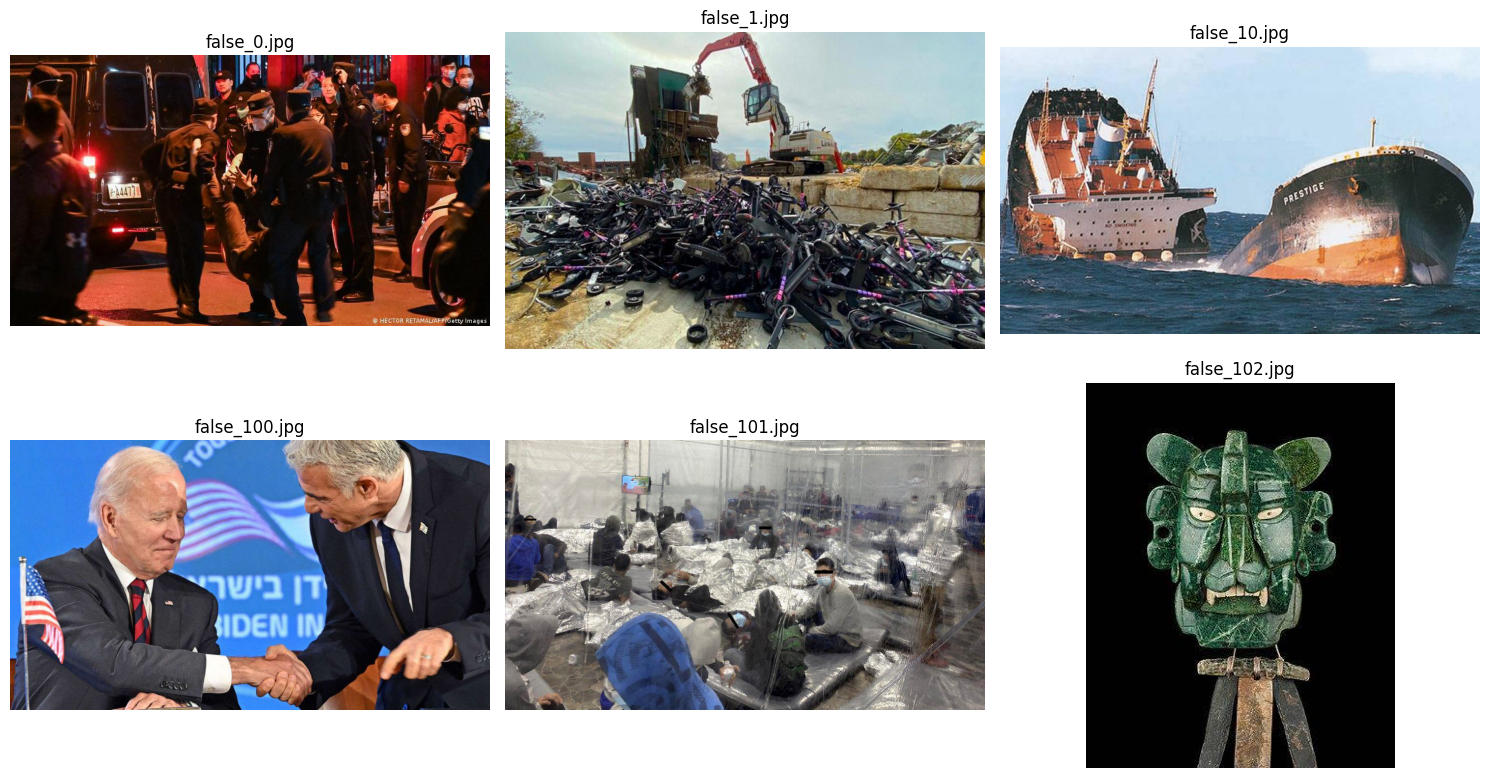

In [31]:

import matplotlib.pyplot as plt
from PIL import Image

sample_images = valid_images[:6]

plt.figure(figsize=(15, 8))

for i, image_path in enumerate(sample_images):
    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [32]:

# Identify extracted images not referenced in the CSV

csv_image_names = set(
    Path(path).name for path in verite_csv["image_path"]
)

extracted_image_names = set(
    path.name for path in extracted_images
)

extra_images = extracted_image_names - csv_image_names

print("Images referenced in CSV:", len(csv_image_names))
print("Images extracted:", len(extracted_image_names))
print("Extra images:", len(extra_images))
print("Extra image filenames:", sorted(extra_images))

# Examine label combinations per image
image_label_summary = (
    verite_csv.groupby("image_path")
    .agg(
        record_count=("label", "count"),
        label_count=("label", "nunique"),
        labels=("label", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

print("\nRecords per image:")
print(image_label_summary["record_count"].value_counts().sort_index())

print("\nImages associated with multiple labels:")
display(
    image_label_summary[
        image_label_summary["label_count"] > 1
    ].head(15)
)


Images referenced in CSV: 663
Images extracted: 664
Extra images: 1
Extra image filenames: ['false_179.jpeg']

Records per image:
record_count
1    325
2    338
Name: count, dtype: int64

Images associated with multiple labels:


,image_path,record_count,label_count,labels
325,images/true_0.jpg,2,2,"miscaptioned, true"
326,images/true_1.jpg,2,2,"miscaptioned, true"
327,images/true_10.jpg,2,2,"miscaptioned, true"
328,images/true_100.jpg,2,2,"miscaptioned, true"
329,images/true_101.jpg,2,2,"miscaptioned, true"
330,images/true_102.jpg,2,2,"miscaptioned, true"
331,images/true_103.jpg,2,2,"miscaptioned, true"
332,images/true_104.jpg,2,2,"miscaptioned, true"
333,images/true_105.jpg,2,2,"miscaptioned, true"
334,images/true_106.jpg,2,2,"miscaptioned, true"


In [33]:

from pathlib import Path
import pandas as pd

# Create a clean copy of the original metadata
clean_verite = verite_csv[
    ["caption", "image_path", "label"]
].copy()

# Add the full path to each verified image
clean_verite["resolved_image_path"] = clean_verite["image_path"].apply(
    lambda x: str(EXTRACTED_IMAGE_DIR / Path(x).name)
)

# Verify all paths again
clean_verite["image_exists"] = clean_verite[
    "resolved_image_path"
].apply(lambda x: Path(x).is_file())

# Stop if any image is missing
assert clean_verite["image_exists"].all(), (
    "Some image paths are missing. Do not save the cleaned dataset yet."
)

# Save cleaned metadata
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "vision"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "verite_cleaned.csv"

clean_verite.to_csv(output_file, index=False)

print("Cleaned metadata saved successfully.")
print("Location:", output_file)
print("Total records:", len(clean_verite))
print("Verified image paths:", clean_verite["image_exists"].sum())
print("Labels:")
print(clean_verite["label"].value_counts())


Cleaned metadata saved successfully.
Location: /content/drive/MyDrive/twincheck/data/processed/vision/verite_cleaned.csv
Total records: 1001
Verified image paths: 1001
Labels:
label
true              338
miscaptioned      338
out-of-context    325
Name: count, dtype: int64


create leakage-safe dataset splits

In [34]:

!pip -q install scikit-learn


In [35]:

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Load cleaned metadata
data = pd.read_csv(
    PROJECT_ROOT / "data/processed/vision/verite_cleaned.csv"
)

# Use image filename as the group identifier
data["image_id"] = data["image_path"].apply(
    lambda x: Path(x).name
)

# Create a stratification label for each image group.
# This is only for approximate balancing; original row labels remain unchanged.
group_labels = (
    data.groupby("image_id")["label"]
    .agg(lambda x: "|".join(sorted(set(x))))
    .reset_index()
)

print("Unique image groups:", len(group_labels))
print("\nGroup label combinations:")
print(group_labels["label"].value_counts())


Unique image groups: 663

Group label combinations:
label
miscaptioned|true    338
out-of-context       325
Name: count, dtype: int64


Data Split

In [36]:

from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

# Recreate the group table
group_labels = (
    data.groupby("image_id")["label"]
    .agg(lambda x: "|".join(sorted(set(x))))
    .reset_index()
)

# First split: 70% training, 30% temporary
train_groups, temp_groups = train_test_split(
    group_labels,
    test_size=0.30,
    random_state=42,
    stratify=group_labels["label"]
)

# Second split: divide temporary groups equally
val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups["label"]
)

# Extract image IDs for each split
train_ids = set(train_groups["image_id"])
val_ids = set(val_groups["image_id"])
test_ids = set(test_groups["image_id"])

# Assign original records to their respective splits
train_data = data[data["image_id"].isin(train_ids)].copy()
val_data = data[data["image_id"].isin(val_ids)].copy()
test_data = data[data["image_id"].isin(test_ids)].copy()

# Verify no image leakage between splits
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Verify every record is assigned exactly once
assert len(train_data) + len(val_data) + len(test_data) == len(data)

# Verify all referenced image paths exist
for split_data in [train_data, val_data, test_data]:
    assert split_data["resolved_image_path"].apply(
        lambda x: Path(x).is_file()
    ).all()

# Save the splits
SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "vision" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_data.to_csv(SPLIT_DIR / "train.csv", index=False)
val_data.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_data.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Dataset splitting completed successfully!")
print("\nRecords in each split:")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

print("\nUnique images in each split:")
print("Training:", len(train_ids))
print("Validation:", len(val_ids))
print("Testing:", len(test_ids))

print("\nNo image leakage detected.")


Dataset splitting completed successfully!

Records in each split:
Training: 701
Validation: 149
Testing: 151

Unique images in each split:
Training: 464
Validation: 99
Testing: 100

No image leakage detected.


Final Split results

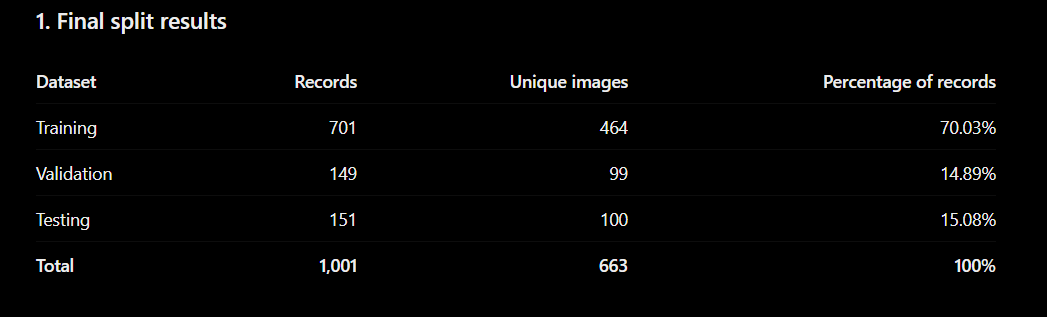

In [37]:

for name, split_data in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Testing", test_data)
]:
    print(f"\n{name} label distribution:")
    print(split_data["label"].value_counts())
    print("\nLabel proportions:")
    print(
        split_data["label"].value_counts(normalize=True).round(3)
    )



Training label distribution:
label
true              237
miscaptioned      237
out-of-context    227
Name: count, dtype: int64

Label proportions:
label
true              0.338
miscaptioned      0.338
out-of-context    0.324
Name: proportion, dtype: float64

Validation label distribution:
label
true              50
miscaptioned      50
out-of-context    49
Name: count, dtype: int64

Label proportions:
label
true              0.336
miscaptioned      0.336
out-of-context    0.329
Name: proportion, dtype: float64

Testing label distribution:
label
true              51
miscaptioned      51
out-of-context    49
Name: count, dtype: int64

Label proportions:
label
true              0.338
miscaptioned      0.338
out-of-context    0.325
Name: proportion, dtype: float64


In [38]:

import json
from datetime import datetime

# Prepare validation report
validation_report = {
    "dataset": "VERITE",
    "total_records": len(data),
    "unique_images": int(data["image_id"].nunique()),
    "extracted_images": len(extracted_images),
    "valid_images": len(valid_images),
    "invalid_images": len(invalid_images),
    "unreferenced_images": sorted(list(extra_images)),
    "missing_image_records": int(
        (~data["resolved_image_path"].apply(
            lambda x: Path(x).is_file()
        )).sum()
    ),
    "split_method": "Stratified group-based split by image_id",
    "random_state": 42,
    "split_ratio": {
        "training": 0.70,
        "validation": 0.15,
        "testing": 0.15
    },
    "splits": {
        "training": {
            "records": len(train_data),
            "unique_images": len(train_ids),
            "labels": train_data["label"].value_counts().to_dict()
        },
        "validation": {
            "records": len(val_data),
            "unique_images": len(val_ids),
            "labels": val_data["label"].value_counts().to_dict()
        },
        "testing": {
            "records": len(test_data),
            "unique_images": len(test_ids),
            "labels": test_data["label"].value_counts().to_dict()
        }
    },
    "image_leakage_detected": False
}

report_path = OUTPUT_DIR / "verite_validation_report.json"

with open(report_path, "w") as f:
    json.dump(validation_report, f, indent=4)

print("Validation report saved:")
print(report_path)


Validation report saved:
/content/drive/MyDrive/twincheck/data/processed/vision/verite_validation_report.json


Verfying the saved report

In [39]:
import json
from pathlib import Path

report_path = Path(
    "/content/drive/MyDrive/twincheck/data/processed/vision/verite_validation_report.json"
)

assert report_path.exists(), "Validation report not found."

with open(report_path, "r") as f:
    report = json.load(f)

print(json.dumps(report, indent=4))

{
    "dataset": "VERITE",
    "total_records": 1001,
    "unique_images": 663,
    "extracted_images": 664,
    "valid_images": 664,
    "invalid_images": 0,
    "unreferenced_images": [
        "false_179.jpeg"
    ],
    "missing_image_records": 0,
    "split_method": "Stratified group-based split by image_id",
    "random_state": 42,
    "split_ratio": {
        "training": 0.7,
        "validation": 0.15,
        "testing": 0.15
    },
    "splits": {
        "training": {
            "records": 701,
            "unique_images": 464,
            "labels": {
                "true": 237,
                "miscaptioned": 237,
                "out-of-context": 227
            }
        },
        "validation": {
            "records": 149,
            "unique_images": 99,
            "labels": {
                "true": 50,
                "miscaptioned": 50,
                "out-of-context": 49
            }
        },
        "testing": {
            "records": 151,
            "uniqu

verite.jsonl

In [40]:
import pandas as pd
import json
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/twincheck")

INPUT_FILE = (
    PROJECT_ROOT /
    "data/processed/vision/verite_cleaned.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "data/processed/vision"
OUTPUT_FILE = OUTPUT_DIR / "verite.jsonl"

# Load cleaned VERITE metadata
df = pd.read_csv(INPUT_FILE)

# Convert each row into a JSON object
records = []

for _, row in df.iterrows():
    record = {
        "caption": row["caption"],
        "image_path": row["image_path"],
        "resolved_image_path": row["resolved_image_path"],
        "label": row["label"]
    }
    records.append(record)

# Save as JSONL
with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    for record in records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("VERITE JSONL saved:", OUTPUT_FILE)
print("Total records:", len(records))
print("Label counts:")
print(df["label"].value_counts())

# Verify the JSONL file
with open(OUTPUT_FILE, "r", encoding="utf-8") as f:
    loaded_records = [json.loads(line) for line in f]

assert len(loaded_records) == len(df)
assert all(Path(r["resolved_image_path"]).is_file() for r in loaded_records)

print("\nJSONL verification passed.")

VERITE JSONL saved: /content/drive/MyDrive/twincheck/data/processed/vision/verite.jsonl
Total records: 1001
Label counts:
label
true              338
miscaptioned      338
out-of-context    325
Name: count, dtype: int64

JSONL verification passed.


Inspect the RED-DOT reference folder

In [41]:
from pathlib import Path

RED_DOT_DIR = Path("/content/twincheck_external/red_dot_reference")

print("RED-DOT folder exists:", RED_DOT_DIR.exists())

if RED_DOT_DIR.exists():
    print("\nFiles and folders:")
    for item in sorted(RED_DOT_DIR.iterdir()):
        print(
            "[DIR] " if item.is_dir() else "[FILE]",
            item.name
        )
else:
    print("RED-DOT reference folder was not found.")

RED-DOT folder exists: True

Files and folders:
[DIR]  .git
[FILE] LICENSE
[FILE] README.md
[DIR]  data
[DIR]  docs
[FILE] requirements.txt
[DIR]  src


Inspect the RED-DOT Directory

In [42]:
from pathlib import Path

RED_DOT_DIR = Path("/content/twincheck_external/red_dot_reference")
DATA_DIR = RED_DOT_DIR / "data"

print("Data directory exists:", DATA_DIR.exists())

print("\nFiles and folders inside data:")

for item in sorted(DATA_DIR.rglob("*")):
    relative_path = item.relative_to(RED_DOT_DIR)

    if item.is_dir():
        print("[DIR] ", relative_path)
    else:
        print("[FILE]", relative_path)

Data directory exists: True

Files and folders inside data:
[DIR]  data/VERITE
[FILE] data/VERITE/VERITE.csv
[FILE] data/VERITE/VERITE_articles.csv
[FILE] data/VERITE/VERITE_clip_image_embeddings_ViTB32.npy
[FILE] data/VERITE/VERITE_clip_text_embeddings_ViTB32.npy
[FILE] data/VERITE/VERITE_external_clip_image_embeddings_ViTB32.npy
[FILE] data/VERITE/VERITE_external_clip_text_embeddings_ViTB32.npy
[FILE] data/VERITE/VERITE_external_image_ids_ViTB32.npy
[FILE] data/VERITE/VERITE_external_text_ids_ViTB32.npy
[FILE] data/VERITE/VERITE_image_ids_ViTB32.npy
[FILE] data/VERITE/VERITE_item_ids_ViTB32.npy
[FILE] data/VERITE/VERITE_ranked_evidence_clip_ViTB32.csv
[FILE] data/VERITE/VERITE_text_ids_ViTB32.npy
[FILE] data/VERITE/VERITE_with_evidence.csv
[DIR]  data/VERITE/external_evidence
[FILE] data/VERITE/external_evidence/false_direct_0.json
[FILE] data/VERITE/external_evidence/false_direct_1.json
[FILE] data/VERITE/external_evidence/false_direct_10.json
[FILE] data/VERITE/external_evidence/fa

In [43]:
from pathlib import Path

README_PATH = Path(
    "/content/twincheck_external/red_dot_reference/README.md"
)

print(README_PATH.read_text(encoding="utf-8"))

# relevant-evidence-detection
Repository for the paper "RED-DOT: Multimodal Fact-checking via Relevant Evidence Detection" published in [IEEE Transactions on Computational Social Systems](https://ieeexplore.ieee.org/abstract/document/10948326).

## Abstract
>*Online misinformation is often multimodal in nature, i.e., it is caused by misleading associations between texts and accompanying images. To support the fact-checking process, researchers have been recently developing automatic multimodal methods that gather and analyze external information, evidence, related to the image-text pairs under examination. However, prior works assumed all collected evidence to be relevant. In this study, we introduce a “Relevant Evidence Detection” (RED) module to discern whether each piece of evidence is relevant, to support or refute the claim. Specifically, we develop the “Relevant Evidence Detection Directed Transformer” (RED-DOT) and explore multiple architectural variants (e.g., single or dual-st

In [44]:
import json
from pathlib import Path
from collections import Counter

EVIDENCE_DIR = Path(
    "/content/twincheck_external/red_dot_reference/"
    "data/VERITE/external_evidence"
)

json_files = list(EVIDENCE_DIR.glob("*.json"))

empty_files = []
non_empty_files = []
invalid_files = []

for file_path in json_files:
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            content = json.load(f)

        if isinstance(content, list) and len(content) == 0:
            empty_files.append(file_path.name)

        elif content:
            non_empty_files.append(file_path.name)

        else:
            empty_files.append(file_path.name)

    except (json.JSONDecodeError, OSError):
        invalid_files.append(file_path.name)

print("Total JSON files:", len(json_files))
print("Non-empty files:", len(non_empty_files))
print("Empty files:", len(empty_files))
print("Invalid files:", len(invalid_files))

print("\nEvidence file categories:")
print(Counter(
    file.name.split("_")[0]
    for file in json_files
))

Total JSON files: 1352
Non-empty files: 1104
Empty files: 248
Invalid files: 0

Evidence file categories:
Counter({'false': 676, 'true': 676})


Save the evidence validation report

In [45]:
import json
from pathlib import Path

REPORT_DIR = Path(
    "/content/drive/MyDrive/twincheck/data/processed/vision"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

evidence_report = {
    "dataset": "VERITE",
    "source": "RED-DOT repository",
    "total_evidence_json_files": len(json_files),
    "non_empty_files": len(non_empty_files),
    "empty_files": len(empty_files),
    "invalid_files": len(invalid_files),
    "filename_categories": {
        "true": 676,
        "false": 676
    },
    "evidence_availability": "External search-result JSON files available",
    "relevance_verified": False
}

report_path = REPORT_DIR / "red_dot_evidence_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(evidence_report, f, indent=4)

print("Evidence report saved:", report_path)
print(json.dumps(evidence_report, indent=4))

Evidence report saved: /content/drive/MyDrive/twincheck/data/processed/vision/red_dot_evidence_report.json
{
    "dataset": "VERITE",
    "source": "RED-DOT repository",
    "total_evidence_json_files": 1352,
    "non_empty_files": 1104,
    "empty_files": 248,
    "invalid_files": 0,
    "filename_categories": {
        "true": 676,
        "false": 676
    },
    "evidence_availability": "External search-result JSON files available",
    "relevance_verified": false
}


In [46]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/twincheck"
)

GENIMAGE_DIR = PROJECT_ROOT / "data/raw/genimage"

print("GenImage directory exists:", GENIMAGE_DIR.exists())

if GENIMAGE_DIR.exists():
    items = list(GENIMAGE_DIR.rglob("*"))

    print("Total files and folders:", len(items))

    for item in items[:50]:
        print(
            "[DIR] " if item.is_dir() else "[FILE]",
            item.relative_to(GENIMAGE_DIR)
        )
else:
    print("GenImage directory is currently empty or missing.")

GenImage directory exists: True
Total files and folders: 0


In [47]:
import shutil
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/twincheck"
)

GENIMAGE_DIR = PROJECT_ROOT / "data/raw/genimage"
GENIMAGE_DIR.mkdir(parents=True, exist_ok=True)

print("Google Drive GenImage directory:", GENIMAGE_DIR)

# Check Colab local storage
total, used, free = shutil.disk_usage("/content")

print("\nColab local storage:")
print(f"Total: {total / (1024**3):.2f} GB")
print(f"Used:  {used / (1024**3):.2f} GB")
print(f"Free:  {free / (1024**3):.2f} GB")

Google Drive GenImage directory: /content/drive/MyDrive/twincheck/data/raw/genimage

Colab local storage:
Total: 107.72 GB
Used:  0.36 GB
Free:  107.34 GB


In [48]:
!pip install -q -U datasets huggingface_hub

In [49]:
from huggingface_hub import HfApi

api = HfApi()

repo_id = "nebula/GenImage-arrow"

info = api.dataset_info(repo_id)

print("Dataset:", info.id)
print("Dataset exists:", info.id == repo_id)
print("Dataset card:", info.card_data)

Dataset: nebula/GenImage-arrow
Dataset exists: True
Dataset card: license: cc-by-nc-sa-4.0
task_categories:
- image-classification
tags:
- synthetic-image-detection
- arrow
configs:
- config_name: default
  default: true
  data_files:
  - split: train
    path: data/train/*/*.arrow
  - split: validation
    path: data/test/*/*.arrow
  - split: test
    path: data/test/*/*.arrow
- config_name: all-test
  data_files:
  - split: test
    path: data/test/*/*.arrow
- config_name: all-train
  data_files:
  - split: train
    path: data/train/*/*.arrow
- config_name: all-validation
  data_files:
  - split: validation
    path: data/test/*/*.arrow
- config_name: adm
  data_files:
  - split: train
    path: data/train/ADM/*.arrow
  - split: validation
    path: data/test/ADM/*.arrow
  - split: test
    path: data/test/ADM/*.arrow
- config_name: adm-train
  data_files:
  - split: train
    path: data/train/ADM/*.arrow
- config_name: adm-test
  data_files:
  - split: test
    path: data/test/ADM/

In [50]:

from huggingface_hub import HfApi

api = HfApi()
repo_id = "nebula/GenImage-arrow"

files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

generators = [
    "stable_diffusion_v_1_4",
    "BigGAN",
    "Midjourney"
]

for generator in generators:
    print(f"\n--- {generator} ---")

    for split in ["train", "test"]:
        prefix = f"data/{split}/{generator}/"
        matching_files = [
            f for f in files if f.startswith(prefix)
        ]

        print(f"{split}: {len(matching_files)} files")

        for filename in matching_files[:3]:
            print(" ", filename)



--- stable_diffusion_v_1_4 ---
train: 195 files
  data/train/stable_diffusion_v_1_4/LICENSE
  data/train/stable_diffusion_v_1_4/bundle_manifest.json
  data/train/stable_diffusion_v_1_4/data-00000-of-00189.arrow
test: 14 files
  data/test/stable_diffusion_v_1_4/LICENSE
  data/test/stable_diffusion_v_1_4/bundle_manifest.json
  data/test/stable_diffusion_v_1_4/data-00000-of-00008.arrow

--- BigGAN ---
train: 54 files
  data/train/BigGAN/LICENSE
  data/train/BigGAN/bundle_manifest.json
  data/train/BigGAN/data-00000-of-00048.arrow
test: 8 files
  data/test/BigGAN/LICENSE
  data/test/BigGAN/bundle_manifest.json
  data/test/BigGAN/data-00000-of-00002.arrow

--- Midjourney ---
train: 482 files
  data/train/Midjourney/LICENSE
  data/train/Midjourney/bundle_manifest.json
  data/train/Midjourney/data-00000-of-00476.arrow
test: 25 files
  data/test/Midjourney/LICENSE
  data/test/Midjourney/bundle_manifest.json
  data/test/Midjourney/data-00000-of-00019.arrow


In [51]:

from huggingface_hub import hf_hub_download
import json
import os

repo_id = "nebula/GenImage-arrow"

folders = [
    "data/train/stable_diffusion_v_1_4",
    "data/train/BigGAN",
    "data/train/Midjourney",
    "data/test/stable_diffusion_v_1_4",
    "data/test/BigGAN",
    "data/test/Midjourney"
]

for folder in folders:
    print("\n" + "=" * 65)
    print(folder)

    manifest_path = hf_hub_download(
        repo_id=repo_id,
        repo_type="dataset",
        filename=f"{folder}/bundle_manifest.json"
    )

    with open(manifest_path, "r") as f:
        manifest = json.load(f)

    print(json.dumps(manifest, indent=2)[:5000])



data/train/stable_diffusion_v_1_4


bundle_manifest.json:   0%|          | 0.00/232 [00:00<?, ?B/s]

{
  "counts": {
    "fake": 161997,
    "real": 162000
  },
  "format": "huggingface-save-to-disk-arrow",
  "generator": "stable_diffusion_v_1_4",
  "rows": 323997,
  "shards": 189,
  "size_bytes": 93059841288,
  "split": "train"
}

data/train/BigGAN


bundle_manifest.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

{
  "counts": {
    "fake": 161996,
    "real": 162000
  },
  "format": "huggingface-save-to-disk-arrow",
  "generator": "BigGAN",
  "rows": 323996,
  "shards": 48,
  "size_bytes": 23385258920,
  "split": "train"
}

data/train/Midjourney


bundle_manifest.json:   0%|          | 0.00/221 [00:00<?, ?B/s]

... (3 outputs left out)

bundle_manifest.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

{
  "counts": {
    "fake": 6000,
    "real": 6000
  },
  "format": "huggingface-save-to-disk-arrow",
  "generator": "BigGAN",
  "rows": 12000,
  "shards": 2,
  "size_bytes": 982920416,
  "split": "test"
}

data/test/Midjourney


bundle_manifest.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

{
  "counts": {
    "fake": 6000,
    "real": 6000
  },
  "format": "huggingface-save-to-disk-arrow",
  "generator": "Midjourney",
  "rows": 12000,
  "shards": 19,
  "size_bytes": 8329105536,
  "split": "test"
}


In [52]:

from huggingface_hub import HfApi

api = HfApi()
repo_id = "nebula/GenImage-arrow"

folders = [
    "data/train/stable_diffusion_v_1_4",
    "data/train/BigGAN",
    "data/test/Midjourney"
]

for folder in folders:
    print("\n" + "=" * 65)
    print(folder)

    info = api.dataset_info(
        repo_id,
        files_metadata=True
    )

    matching = [
        item for item in info.siblings
        if item.rfilename.startswith(folder + "/")
        and item.rfilename.endswith(".arrow")
    ]

    total_bytes = 0

    for item in matching:
        size = getattr(item, "size", None)

        if size is not None:
            total_bytes += size

    print("Arrow shard count:", len(matching))
    print("Known total size (GB):", round(total_bytes / 1e9, 2))

    print("\nFirst five shards:")
    for item in matching[:5]:
        size = getattr(item, "size", None)
        print(
            item.rfilename,
            "|",
            round(size / 1e6, 2) if size is not None else "Size unknown",
            "MB"
        )



data/train/stable_diffusion_v_1_4
Arrow shard count: 189
Known total size (GB): 93.06

First five shards:
data/train/stable_diffusion_v_1_4/data-00000-of-00189.arrow | 500.63 MB
data/train/stable_diffusion_v_1_4/data-00001-of-00189.arrow | 493.07 MB
data/train/stable_diffusion_v_1_4/data-00002-of-00189.arrow | 501.12 MB
data/train/stable_diffusion_v_1_4/data-00003-of-00189.arrow | 502.04 MB
data/train/stable_diffusion_v_1_4/data-00004-of-00189.arrow | 497.07 MB

data/train/BigGAN
Arrow shard count: 48
Known total size (GB): 23.39

First five shards:
data/train/BigGAN/data-00000-of-00048.arrow | 498.41 MB
data/train/BigGAN/data-00001-of-00048.arrow | 505.14 MB
data/train/BigGAN/data-00002-of-00048.arrow | 509.47 MB
data/train/BigGAN/data-00003-of-00048.arrow | 509.93 MB
data/train/BigGAN/data-00004-of-00048.arrow | 505.27 MB

data/test/Midjourney
Arrow shard count: 19
Known total size (GB): 8.33

First five shards:
data/test/Midjourney/data-00000-of-00019.arrow | 510.83 MB
data/test/Mi

In [1]:
import datasets
import pyarrow

print("Datasets version:", datasets.__version__)
print("PyArrow version:", pyarrow.__version__)

from datasets import get_dataset_config_info

print("Import successful!")


Datasets version: 5.2.0
PyArrow version: 26.0.1
Import successful!


In [2]:

from datasets import get_dataset_config_info

repo_id = "nebula/GenImage-arrow"

for config_name in ["sd14", "biggan", "midjourney"]:
    print("\n" + "=" * 60)
    print("CONFIGURATION:", config_name)

    info = get_dataset_config_info(
        repo_id,
        config_name=config_name
    )

    print("\nFeatures:")
    print(info.features)

    print("\nDataset description:")
    print(
        info.description[:1000]
        if info.description
        else "Not provided"
    )



CONFIGURATION: sd14


README.md:   0%|          | 0.00/9.23k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/189 [00:00<?, ?it/s]

... (9 outputs left out)

Resolving data files:   0%|          | 0/476 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]


Features:
{'image_path': Value('string'), 'md5': Value('string'), 'width': Value('int64'), 'height': Value('int64'), 'image': Value('binary'), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['ADM', 'BigGAN', 'glide', 'Midjourney', 'stable_diffusion_v_1_4', 'stable_diffusion_v_1_5', 'VQDM', 'wukong'])}

Dataset description:
Not provided


In [3]:

from datasets import get_dataset_config_info

repo_id = "nebula/GenImage-arrow"

for config_name in ["sd14", "biggan", "midjourney"]:
    info = get_dataset_config_info(
        repo_id,
        config_name=config_name
    )

    print(f"\n{config_name}")
    print("Label mapping:",
          info.features["label"].names)
    print("Generator mapping:",
          info.features["generator"].names)


Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/189 [00:00<?, ?it/s]


sd14
Label mapping: ['real', 'fake']
Generator mapping: ['ADM', 'BigGAN', 'glide', 'Midjourney', 'stable_diffusion_v_1_4', 'stable_diffusion_v_1_5', 'VQDM', 'wukong']


Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

... (7 outputs left out)

Resolving data files:   0%|          | 0/476 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]


midjourney
Label mapping: ['real', 'fake']
Generator mapping: ['ADM', 'BigGAN', 'glide', 'Midjourney', 'stable_diffusion_v_1_4', 'stable_diffusion_v_1_5', 'VQDM', 'wukong']


In [5]:

import os

print("File size (MB):", round(os.path.getsize(arrow_path) / 1e6, 2))

with open(arrow_path, "rb") as f:
    header = f.read(32)

print("First 32 bytes:", header)
print("File signature:", repr(header[:8]))


File size (MB): 498.41
First 32 bytes: b'\xff\xff\xff\xff\xc8\x03\x00\x00\x10\x00\x00\x00\x00\x00\n\x00\x0e\x00\x06\x00\x05\x00\x08\x00\n\x00\x00\x00\x00\x01\x04\x00'
File signature: b'\xff\xff\xff\xff\xc8\x03\x00\x00'


In [6]:

import pyarrow.ipc as ipc

try:
    reader = ipc.open_stream(arrow_path)

    print("SUCCESS: Opened as Arrow IPC stream")
    print("\nSchema:")
    print(reader.schema)

    batch = reader.read_next_batch()

    print("\nFirst batch rows:", batch.num_rows)

except Exception as e:
    print("Could not open as Arrow IPC stream:")
    print(type(e).__name__, str(e))


SUCCESS: Opened as Arrow IPC stream

Schema:
image_path: string
md5: string
width: int64
height: int64
image: binary
label: int64
generator: int64
-- schema metadata --
huggingface: '{"info": {"features": {"image_path": {"dtype": "string", "_' + 427

First batch rows: 500


In [7]:

from PIL import Image
from io import BytesIO
import hashlib

# Read the first batch (500 records)
batch = reader.read_next_batch()

# Get the class mappings from the dataset metadata
from datasets import get_dataset_config_info

info = get_dataset_config_info(
    "nebula/GenImage-arrow",
    config_name="biggan"
)

label_names = info.features["label"].names
generator_names = info.features["generator"].names

print("Label mapping:", label_names)
print("Generator mapping:", generator_names)

# Inspect five records
for i in range(5):
    row = batch.slice(i, 1).to_pylist()[0]

    print(f"\n--- Record {i + 1} ---")
    print("Image path:", row["image_path"])
    print("MD5:", row["md5"])
    print("Width:", row["width"])
    print("Height:", row["height"])
    print("Label:", label_names[row["label"]])
    print("Generator:", generator_names[row["generator"]])
    print("Image bytes:", len(row["image"]))

    try:
        img = Image.open(BytesIO(row["image"]))
        img.verify()
        print("Image decoding: SUCCESS")
    except Exception as e:
        print("Image decoding: FAILED", str(e))


Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Label mapping: ['real', 'fake']
Generator mapping: ['ADM', 'BigGAN', 'glide', 'Midjourney', 'stable_diffusion_v_1_4', 'stable_diffusion_v_1_5', 'VQDM', 'wukong']

--- Record 1 ---
Image path: BigGAN/train/ai/003_biggan_00017.png
MD5: 88c612b85093b48ff0c6290052de3d4e
Width: 128
Height: 128
Label: fake
Generator: BigGAN
Image bytes: 22778
Image decoding: SUCCESS

--- Record 2 ---
Image path: BigGAN/train/ai/003_biggan_00018.png
MD5: 8d38a6f2cd2c756da676813649169f20
Width: 128
Height: 128
Label: fake
Generator: BigGAN
Image bytes: 20817
Image decoding: SUCCESS

--- Record 3 ---
Image path: BigGAN/train/ai/003_biggan_00021.png
MD5: 441d71d94e867870566cb5db960a8bb2
Width: 128
Height: 128
Label: fake
Generator: BigGAN
Image bytes: 9626
Image decoding: SUCCESS

--- Record 4 ---
Image path: BigGAN/train/ai/003_biggan_00022.png
MD5: fec3bc1fb3771c8af4c0a17cc8bdc430
Width: 128
Height: 128
Label: fake
Generator: BigGAN
Image bytes: 12289
Image decoding: SUCCESS

--- Record 5 ---
Image path: BigGA

In [8]:

import pyarrow.ipc as ipc
from collections import Counter

# Reopen the shard from the beginning
reader_check = ipc.open_stream(arrow_path)

label_counts = Counter()
generator_counts = Counter()
md5_hashes = set()
duplicate_hashes = set()
dimension_counts = Counter()
total_records = 0
missing_md5 = 0

for batch in reader_check:
    total_records += batch.num_rows

    # Read metadata columns only
    labels = batch.column("label").to_pylist()
    generators = batch.column("generator").to_pylist()
    hashes = batch.column("md5").to_pylist()
    widths = batch.column("width").to_pylist()
    heights = batch.column("height").to_pylist()

    label_counts.update(labels)
    generator_counts.update(generators)

    for value in hashes:
        if not value:
            missing_md5 += 1
        elif value in md5_hashes:
            duplicate_hashes.add(value)
        else:
            md5_hashes.add(value)

    dimension_counts.update(zip(widths, heights))

print("Total records:", total_records)

print("\nLabel distribution:")
for label_id, count in sorted(label_counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerator distribution:")
for generator_id, count in sorted(generator_counts.items()):
    print(generator_names[generator_id], ":", count)

print("\nUnique MD5 hashes:", len(md5_hashes))
print("Duplicate MD5 hashes:", len(duplicate_hashes))
print("Missing MD5 values:", missing_md5)

print("\nImage dimensions:")
for dimensions, count in dimension_counts.most_common(10):
    print(f"{dimensions[0]} x {dimensions[1]}: {count}")


Total records: 15500

Label distribution:
fake : 15500

Generator distribution:
BigGAN : 15500

Unique MD5 hashes: 15500
Duplicate MD5 hashes: 0
Missing MD5 values: 0

Image dimensions:
128 x 128: 15500


In [9]:

from huggingface_hub import hf_hub_download
import pyarrow.ipc as ipc
from collections import Counter

repo_id = "nebula/GenImage-arrow"

filename = (
    "data/train/BigGAN/"
    "data-00047-of-00048.arrow"
)

print("Downloading final BigGAN training shard...")

last_arrow_path = hf_hub_download(
    repo_id=repo_id,
    repo_type="dataset",
    filename=filename
)

print("Download complete.")

# Open as Arrow IPC stream
last_reader = ipc.open_stream(last_arrow_path)

label_counts = Counter()
generator_counts = Counter()
path_examples = []

total = 0

for batch in last_reader:
    total += batch.num_rows

    label_counts.update(batch.column("label").to_pylist())
    generator_counts.update(batch.column("generator").to_pylist())

    paths = batch.column("image_path").to_pylist()

    # Keep only a few example paths
    if len(path_examples) < 5:
        path_examples.extend(paths[:5 - len(path_examples)])

print("\nTotal records:", total)

print("\nLabel distribution:")
for label_id, count in sorted(label_counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerator distribution:")
for generator_id, count in sorted(generator_counts.items()):
    print(generator_names[generator_id], ":", count)

print("\nExample image paths:")
for path in path_examples:
    print(path)


data/train/BigGAN/data-00047-of-00048.ar(…): reconstructing file:   0%|          |  0.00B /  406MB            

data/train/BigGAN/data-00047-of-00048.ar(…): downloading bytes:           |  0.00B            

Download complete.

Total records: 2996

Label distribution:
real : 2996

Generator distribution:
BigGAN : 2996

Example image paths:
BigGAN/train/nature/n09835506_22587.JPEG
BigGAN/train/nature/n09835506_22639.JPEG
BigGAN/train/nature/n09835506_22681.JPEG
BigGAN/train/nature/n09835506_22736.JPEG
BigGAN/train/nature/n09835506_2357.JPEG


In [10]:

from huggingface_hub import hf_hub_download
import pyarrow.ipc as ipc
from collections import Counter

filename = (
    "data/train/BigGAN/"
    "data-00046-of-00048.arrow"
)

print("Downloading second-last BigGAN shard...")

shard_path_46 = hf_hub_download(
    repo_id="nebula/GenImage-arrow",
    repo_type="dataset",
    filename=filename
)

reader_46 = ipc.open_stream(shard_path_46)

counts = Counter()
total = 0
examples = []

for batch in reader_46:
    total += batch.num_rows
    counts.update(batch.column("label").to_pylist())

    if len(examples) < 3:
        examples.extend(
            batch.column("image_path").to_pylist()[:3-len(examples)]
        )

print("\nTotal records:", total)

print("\nLabel distribution:")
for label_id, count in sorted(counts.items()):
    print(label_names[label_id], ":", count)

print("\nExample paths:")
for path in examples:
    print(path)


data/train/BigGAN/data-00046-of-00048.ar(…): reconstructing file:   0%|          |  0.00B /  449MB            

data/train/BigGAN/data-00046-of-00048.ar(…): downloading bytes:           |  0.00B            


Total records: 3500

Label distribution:
real : 3500

Example paths:
BigGAN/train/nature/n07831146_8728.JPEG
BigGAN/train/nature/n07831146_8745.JPEG
BigGAN/train/nature/n07831146_8760.JPEG


In [11]:

from huggingface_hub import hf_hub_download
import pyarrow.ipc as ipc
from collections import Counter

filename = (
    "data/train/BigGAN/"
    "data-00024-of-00048.arrow"
)

print("Downloading middle BigGAN shard...")

middle_path = hf_hub_download(
    repo_id="nebula/GenImage-arrow",
    repo_type="dataset",
    filename=filename
)

middle_reader = ipc.open_stream(middle_path)

counts = Counter()
generators = Counter()
total = 0
examples = []

for batch in middle_reader:
    total += batch.num_rows

    counts.update(batch.column("label").to_pylist())
    generators.update(batch.column("generator").to_pylist())

    if len(examples) < 5:
        examples.extend(
            batch.column("image_path").to_pylist()[:5-len(examples)]
        )

print("\nTotal records:", total)

print("\nLabels:")
for label_id, count in sorted(counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerators:")
for generator_id, count in sorted(generators.items()):
    print(generator_names[generator_id], ":", count)

print("\nExample paths:")
for path in examples:
    print(path)


data/train/BigGAN/data-00024-of-00048.ar(…): reconstructing file:   0%|          |  0.00B /  507MB            

data/train/BigGAN/data-00024-of-00048.ar(…): downloading bytes:           |  0.00B            


Total records: 4000

Labels:
real : 4000

Generators:
BigGAN : 4000

Example paths:
BigGAN/train/nature/n02484975_3679.JPEG
BigGAN/train/nature/n02484975_3856.JPEG
BigGAN/train/nature/n02484975_3918.JPEG
BigGAN/train/nature/n02484975_4224.JPEG
BigGAN/train/nature/n02484975_4236.JPEG


In [12]:

from datasets import load_dataset

repo_id = "nebula/GenImage-arrow"

print("Loading a small streaming sample...")

stream = load_dataset(
    repo_id,
    name="biggan-train",
    split="train",
    streaming=True
)

print("\nFirst 10 records:")

for i, row in enumerate(stream.take(10)):
    print(
        i + 1,
        "| label:", row["label"],
        "| generator:", row["generator"],
        "| image:", type(row["image"]),
        "| MD5:", row["md5"]
    )


Loading a small streaming sample...


Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]


First 10 records:
1 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: 9f65e265ad0931c49fa2b055f071a2fa
2 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: 336be20d7f6323235056537740b1ac9d
3 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: 2b8bc8603fc52894d1740f56c4afdfa9
4 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: 7741f5f43f82c3dad6e3b3955a496e83
5 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: d55eae2a19a44e62ee40f7d6d8a8c17f
6 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: 187de12afcb2b82a18d0fd18d95c9dc4
7 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: e6098ba3a863ea0129462c4a5b47f832
8 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: 93fde45565e23781c78faf9bdfead700
9 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: ab0ce9c93ad42b484401a201d4bd8b81
10 | label: 1 | generator: 1 | image: <class 'bytes'> | MD5: 72ad93b0623f64d4c42f29e8d6b4454f


inspect the Stable Diffusion first shard

In [13]:

from huggingface_hub import hf_hub_download
import pyarrow.ipc as ipc
from collections import Counter

filename = (
    "data/train/stable_diffusion_v_1_4/"
    "data-00000-of-00189.arrow"
)

print("Downloading first Stable Diffusion shard...")

sd_arrow_path = hf_hub_download(
    repo_id="nebula/GenImage-arrow",
    repo_type="dataset",
    filename=filename
)

sd_reader = ipc.open_stream(sd_arrow_path)

label_counts = Counter()
generator_counts = Counter()
total = 0
md5_values = set()
missing_md5 = 0
duplicate_count = 0

for batch in sd_reader:
    total += batch.num_rows

    label_counts.update(batch.column("label").to_pylist())
    generator_counts.update(batch.column("generator").to_pylist())

    for value in batch.column("md5").to_pylist():
        if not value:
            missing_md5 += 1
        elif value in md5_values:
            duplicate_count += 1
        else:
            md5_values.add(value)

print("\nTotal records:", total)

print("\nLabels:")
for label_id, count in sorted(label_counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerators:")
for generator_id, count in sorted(generator_counts.items()):
    print(generator_names[generator_id], ":", count)

print("\nUnique MD5 hashes:", len(md5_values))
print("Duplicate records:", duplicate_count)
print("Missing MD5 values:", missing_md5)


data/train/stable_diffusion_v_1_4/data-0(…): reconstructing file:   0%|          |  0.00B /  501MB            

data/train/stable_diffusion_v_1_4/data-0(…): downloading bytes:           |  0.00B            


Total records: 1720

Labels:
real : 839
fake : 881

Generators:
stable_diffusion_v_1_4 : 1720

Unique MD5 hashes: 1720
Duplicate records: 0
Missing MD5 values: 0


inspect the second Stable Diffusion shard

In [14]:

from huggingface_hub import hf_hub_download
import pyarrow.ipc as ipc
from collections import Counter

filename = (
    "data/train/stable_diffusion_v_1_4/"
    "data-00001-of-00189.arrow"
)

print("Downloading second Stable Diffusion shard...")

sd_arrow_path_1 = hf_hub_download(
    repo_id="nebula/GenImage-arrow",
    repo_type="dataset",
    filename=filename
)

reader = ipc.open_stream(sd_arrow_path_1)

label_counts = Counter()
generator_counts = Counter()
md5_hashes = set()
duplicate_count = 0
missing_md5 = 0
total = 0

for batch in reader:
    total += batch.num_rows

    label_counts.update(batch.column("label").to_pylist())
    generator_counts.update(batch.column("generator").to_pylist())

    for value in batch.column("md5").to_pylist():
        if not value:
            missing_md5 += 1
        elif value in md5_hashes:
            duplicate_count += 1
        else:
            md5_hashes.add(value)

print("\nTotal records:", total)

print("\nLabels:")
for label_id, count in sorted(label_counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerators:")
for generator_id, count in sorted(generator_counts.items()):
    print(generator_names[generator_id], ":", count)

print("\nUnique MD5 hashes:", len(md5_hashes))
print("Duplicate records within shard:", duplicate_count)
print("Missing MD5 values:", missing_md5)


data/train/stable_diffusion_v_1_4/data-0(…): reconstructing file:   0%|          |  0.00B /  493MB            

data/train/stable_diffusion_v_1_4/data-0(…): downloading bytes:           |  0.00B            


Total records: 1782

Labels:
real : 937
fake : 845

Generators:
stable_diffusion_v_1_4 : 1782

Unique MD5 hashes: 1782
Duplicate records within shard: 0
Missing MD5 values: 0


In [15]:

import pyarrow.ipc as ipc

def get_md5_hashes(path):
    hashes = set()

    with ipc.open_stream(path) as reader:
        for batch in reader:
            hashes.update(
                value
                for value in batch.column("md5").to_pylist()
                if value
            )

    return hashes

hashes_0 = get_md5_hashes(sd_arrow_path)
hashes_1 = get_md5_hashes(sd_arrow_path_1)

overlap = hashes_0.intersection(hashes_1)

print("Shard 00000 unique hashes:", len(hashes_0))
print("Shard 00001 unique hashes:", len(hashes_1))
print("Hashes shared between shards:", len(overlap))
print(
    "Unique images across both:",
    len(hashes_0.union(hashes_1))
)


Shard 00000 unique hashes: 1720
Shard 00001 unique hashes: 1782
Hashes shared between shards: 0
Unique images across both: 3502


inspect Midjourney's official test partition

Schema

In [17]:

import pyarrow.ipc as ipc

mj_reader = ipc.open_stream(mj_path)

print("Midjourney test Arrow schema:")
print(mj_reader.schema)

print("\nAvailable columns:")
print(mj_reader.schema.names)

print("\nFirst batch information:")
first_batch = mj_reader.read_next_batch()
print("Number of records:", first_batch.num_rows)

for column in first_batch.schema.names:
    print(column, ":", first_batch.column(column).type)


Midjourney test Arrow schema:
image_path: string
image: binary
label: int64
generator: int64
-- schema metadata --
huggingface: '{"info": {"features": {"image_path": {"dtype": "string", "_' + 286

Available columns:
['image_path', 'image', 'label', 'generator']

First batch information:
Number of records: 18
image_path : string
image : binary
label : int64
generator : int64


In [18]:

import pyarrow.ipc as ipc
import hashlib
from collections import Counter

# Reopen the existing downloaded shard
mj_reader = ipc.open_stream(mj_path)

label_counts = Counter()
generator_counts = Counter()
md5_hashes = set()

duplicate_count = 0
missing_images = 0
total_records = 0

for batch in mj_reader:
    total_records += batch.num_rows

    labels = batch.column("label").to_pylist()
    generators = batch.column("generator").to_pylist()
    images = batch.column("image").to_pylist()

    label_counts.update(labels)
    generator_counts.update(generators)

    for image_bytes in images:
        if not image_bytes:
            missing_images += 1
            continue

        # Calculate MD5 directly from image bytes
        image_hash = hashlib.md5(image_bytes).hexdigest()

        if image_hash in md5_hashes:
            duplicate_count += 1
        else:
            md5_hashes.add(image_hash)

print("Total records:", total_records)

print("\nLabel distribution:")
for label_id, count in sorted(label_counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerator distribution:")
for generator_id, count in sorted(generator_counts.items()):
    print(generator_names[generator_id], ":", count)

print("\nImage integrity:")
print("Unique image hashes:", len(md5_hashes))
print("Duplicate images:", duplicate_count)
print("Missing images:", missing_images)


Total records: 3764

Label distribution:
real : 3764

Generator distribution:
Midjourney : 3764

Image integrity:
Unique image hashes: 3764
Duplicate images: 0
Missing images: 0


In [19]:

from huggingface_hub import hf_hub_download
import pyarrow.ipc as ipc
import hashlib
from collections import Counter

filename = (
    "data/test/Midjourney/"
    "data-00018-of-00019.arrow"
)

print("Downloading final Midjourney test shard...")

mj_last_path = hf_hub_download(
    repo_id="nebula/GenImage-arrow",
    repo_type="dataset",
    filename=filename
)

reader = ipc.open_stream(mj_last_path)

label_counts = Counter()
generator_counts = Counter()
hashes = set()

total = 0
duplicates = 0
missing_images = 0

for batch in reader:
    total += batch.num_rows

    labels = batch.column("label").to_pylist()
    generators = batch.column("generator").to_pylist()
    images = batch.column("image").to_pylist()

    label_counts.update(labels)
    generator_counts.update(generators)

    for image_bytes in images:
        if not image_bytes:
            missing_images += 1
            continue

        image_hash = hashlib.md5(image_bytes).hexdigest()

        if image_hash in hashes:
            duplicates += 1
        else:
            hashes.add(image_hash)

print("\nTotal records:", total)

print("\nLabels:")
for label_id, count in sorted(label_counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerators:")
for generator_id, count in sorted(generator_counts.items()):
    print(generator_names[generator_id], ":", count)

print("\nUnique image hashes:", len(hashes))
print("Duplicate images:", duplicates)
print("Missing images:", missing_images)


data/test/Midjourney/data-00018-of-00019(…): reconstructing file:   0%|          |  0.00B /  297MB            

data/test/Midjourney/data-00018-of-00019(…): downloading bytes:           |  0.00B            


Total records: 244

Labels:
fake : 244

Generators:
Midjourney : 244

Unique image hashes: 244
Duplicate images: 0
Missing images: 0


In [20]:

from datasets import load_dataset
from collections import Counter
import hashlib

repo_id = "nebula/GenImage-arrow"

print("Starting complete Midjourney test verification...")

stream = load_dataset(
    repo_id,
    name="midjourney-test",
    split="test",
    streaming=True
)

label_counts = Counter()
generator_counts = Counter()

image_hashes = set()
duplicate_count = 0
missing_images = 0
total_records = 0

for row in stream:
    total_records += 1

    label_counts[row["label"]] += 1
    generator_counts[row["generator"]] += 1

    image_bytes = row["image"]

    if not image_bytes:
        missing_images += 1
        continue

    image_hash = hashlib.md5(image_bytes).hexdigest()

    if image_hash in image_hashes:
        duplicate_count += 1
    else:
        image_hashes.add(image_hash)

    if total_records % 1000 == 0:
        print("Processed:", total_records)

print("\n========== FINAL REPORT ==========")

print("Total records:", total_records)

print("\nLabel distribution:")
for label_id, count in sorted(label_counts.items()):
    print(label_names[label_id], ":", count)

print("\nGenerator distribution:")
for generator_id, count in sorted(generator_counts.items()):
    print(generator_names[generator_id], ":", count)

print("\nImage integrity:")
print("Unique image hashes:", len(image_hashes))
print("Duplicate images:", duplicate_count)
print("Missing images:", missing_images)


Starting complete Midjourney test verification...


Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Processed: 1000
Processed: 2000
Processed: 3000
Processed: 4000
Processed: 5000
Processed: 6000
Processed: 7000
Processed: 8000
Processed: 9000
Processed: 10000
Processed: 11000
Processed: 12000

========== FINAL REPORT ==========
Total records: 12000

Label distribution:
real : 6000
fake : 6000

Generator distribution:
Midjourney : 12000

Image integrity:
Unique image hashes: 11998
Duplicate images: 2
Missing images: 0


In [21]:

from datasets import load_dataset
from collections import defaultdict
import hashlib

repo_id = "nebula/GenImage-arrow"

stream = load_dataset(
    repo_id,
    name="midjourney-test",
    split="test",
    streaming=True
)

hash_records = defaultdict(list)

for row in stream:
    image_bytes = row["image"]

    if not image_bytes:
        continue

    image_hash = hashlib.md5(image_bytes).hexdigest()

    hash_records[image_hash].append({
        "image_path": row["image_path"],
        "label": row["label"],
        "generator": row["generator"]
    })

duplicates = {
    image_hash: records
    for image_hash, records in hash_records.items()
    if len(records) > 1
}

print("Duplicate hash groups:", len(duplicates))

for image_hash, records in duplicates.items():
    print("\nMD5:", image_hash)

    for record in records:
        print(
            "Path:", record["image_path"],
            "| Label:", record["label"],
            "| Generator:", record["generator"]
        )


Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Duplicate hash groups: 2

MD5: 7464e6b40fa93a7ce70c1052fcfab729
Path: Midjourney/test/nature/ILSVRC2012_val_00007862.JPEG | Label: 0 | Generator: 3
Path: Midjourney/test/nature/ILSVRC2012_val_00041481.JPEG | Label: 0 | Generator: 3

MD5: 648afa6a6a467360d77879c819a5d422
Path: Midjourney/test/nature/ILSVRC2012_val_00018859.JPEG | Label: 0 | Generator: 3
Path: Midjourney/test/nature/ILSVRC2012_val_00042484.JPEG | Label: 0 | Generator: 3


In [22]:

import pandas as pd
import os

duplicate_report = [
    {
        "md5": "7464e6b40fa93a7ce70c1052fcfab729",
        "retained_path": "Midjourney/test/nature/ILSVRC2012_val_00007862.JPEG",
        "excluded_path": "Midjourney/test/nature/ILSVRC2012_val_00041481.JPEG",
        "label": "real",
        "reason": "Exact duplicate image"
    },
    {
        "md5": "648afa6a6a467360d77879c819a5d422",
        "retained_path": "Midjourney/test/nature/ILSVRC2012_val_00018859.JPEG",
        "excluded_path": "Midjourney/test/nature/ILSVRC2012_val_00042484.JPEG",
        "label": "real",
        "reason": "Exact duplicate image"
    }
]

report = pd.DataFrame(duplicate_report)

save_path = (
    "/content/drive/MyDrive/twincheck/"
    "data/processed/vision/"
    "midjourney_test_duplicate_report.csv"
)

os.makedirs(os.path.dirname(save_path), exist_ok=True)

report.to_csv(save_path, index=False)

print("Duplicate report saved:", save_path)
print(report)


Duplicate report saved: /content/drive/MyDrive/twincheck/data/processed/vision/midjourney_test_duplicate_report.csv
                                md5  \
0  7464e6b40fa93a7ce70c1052fcfab729   
1  648afa6a6a467360d77879c819a5d422   

                                       retained_path  \
0  Midjourney/test/nature/ILSVRC2012_val_00007862...   
1  Midjourney/test/nature/ILSVRC2012_val_00018859...   

                                       excluded_path label  \
0  Midjourney/test/nature/ILSVRC2012_val_00041481...  real   
1  Midjourney/test/nature/ILSVRC2012_val_00042484...  real   

                  reason  
0  Exact duplicate image  
1  Exact duplicate image  


In [23]:

import hashlib
import pandas as pd
from datasets import load_dataset
from pathlib import Path

# Project paths
PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the Midjourney test partition
dataset = load_dataset(
    "nebula/GenImage-arrow",
    name="midjourney-test",
    split="test",
    streaming=True
)

# These are the two duplicate images we already identified.
# We retain the first image in each pair and exclude the second.
excluded_paths = {
    "Midjourney/test/nature/ILSVRC2012_val_00041481.JPEG",
    "Midjourney/test/nature/ILSVRC2012_val_00042484.JPEG"
}

records = []
seen_hashes = set()

for i, item in enumerate(dataset):
    image_bytes = item["image"]
    image_path = item["image_path"]

    if image_bytes is None:
        continue

    image_hash = hashlib.md5(image_bytes).hexdigest()

    # Exclude the two previously identified duplicate paths
    if image_path in excluded_paths:
        continue

    # Keep only the first occurrence of each image hash
    if image_hash in seen_hashes:
        continue

    seen_hashes.add(image_hash)

    records.append({
        "image_path": image_path,
        "md5": image_hash,
        "label": item["label"],
        "generator": item["generator"]
    })

    if (i + 1) % 1000 == 0:
        print(f"Processed {i + 1} records")

# Save manifest
manifest = pd.DataFrame(records)

output_path = OUTPUT_DIR / "midjourney_test_unique_manifest.csv"
manifest.to_csv(output_path, index=False)

print("\nManifest saved:", output_path)
print("\nTotal unique images:", len(manifest))
print("\nLabel counts:")
print(manifest["label"].value_counts().sort_index())
print("\nUnique hashes:", manifest["md5"].nunique())


Resolving data files:   0%|          | 0/1306 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Processed 1000 records
Processed 2000 records
Processed 3000 records
Processed 4000 records
Processed 5000 records
Processed 6000 records
Processed 7000 records
Processed 8000 records
Processed 9000 records
Processed 10000 records
Processed 11000 records
Processed 12000 records

Manifest saved: /content/drive/MyDrive/twincheck/data/processed/vision/midjourney_test_unique_manifest.csv

Total unique images: 11998

Label counts:
label
0    5998
1    6000
Name: count, dtype: int64

Unique hashes: 11998


Check candidate BigGAN real images against Midjourney

In [24]:

import hashlib
import pandas as pd
import pyarrow.ipc as ipc
from pathlib import Path
from huggingface_hub import hf_hub_download

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"

# Load the Midjourney test manifest
midjourney = pd.read_csv(
    OUTPUT_DIR / "midjourney_test_unique_manifest.csv"
)

midjourney_hashes = set(midjourney["md5"])

# Previously inspected BigGAN shards containing real images
shard_files = [
    "data/train/BigGAN/data-00024-of-00048.arrow",
    "data/train/BigGAN/data-00046-of-00048.arrow",
    "data/train/BigGAN/data-00047-of-00048.arrow"
]

records = []

for shard in shard_files:
    print(f"\nProcessing: {shard}")

    local_path = hf_hub_download(
        repo_id="nebula/GenImage-arrow",
        filename=shard,
        repo_type="dataset"
    )

    with open(local_path, "rb") as f:
        reader = ipc.open_stream(f)

        for batch in reader:
            for item in batch.to_pylist():

                # We expect these selected shards to contain real images.
                if item["label"] != 0:
                    continue

                image_bytes = item["image"]
                image_hash = hashlib.md5(image_bytes).hexdigest()

                records.append({
                    "image_path": item["image_path"],
                    "md5": image_hash,
                    "label": item["label"],
                    "source_shard": shard
                })

# Build candidate real-image manifest
biggan_real = pd.DataFrame(records)

# Check duplicate hashes within the selected BigGAN shards
duplicate_count = biggan_real["md5"].duplicated().sum()

# Check overlap with the held-out Midjourney test images
biggan_real["midjourney_overlap"] = (
    biggan_real["md5"].isin(midjourney_hashes)
)

overlap_count = biggan_real["midjourney_overlap"].sum()

# Save candidate manifest
biggan_real.to_csv(
    OUTPUT_DIR / "biggan_candidate_real_manifest.csv",
    index=False
)

print("\n========== RESULTS ==========")
print("Candidate BigGAN real images:", len(biggan_real))
print("Unique BigGAN real hashes:", biggan_real["md5"].nunique())
print("Duplicate hashes within selected shards:", duplicate_count)
print("Overlaps with Midjourney test:", overlap_count)
print("Unique real images without Midjourney overlap:",
      biggan_real.loc[
          ~biggan_real["midjourney_overlap"], "md5"
      ].nunique())

print("\nSaved candidate manifest.")



Processing: data/train/BigGAN/data-00024-of-00048.arrow

Processing: data/train/BigGAN/data-00046-of-00048.arrow

Processing: data/train/BigGAN/data-00047-of-00048.arrow

========== RESULTS ==========
Candidate BigGAN real images: 10496
Unique BigGAN real hashes: 10493
Duplicate hashes within selected shards: 3
Overlaps with Midjourney test: 0
Unique real images without Midjourney overlap: 10493

Saved candidate manifest.


Remove the three duplicate records and prepare the real-image pool

In [25]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"

# Load candidate BigGAN real images
biggan_real = pd.read_csv(
    OUTPUT_DIR / "biggan_candidate_real_manifest.csv"
)

# Remove duplicate images using MD5
biggan_real_clean = biggan_real.drop_duplicates(
    subset="md5",
    keep="first"
).copy()

# Confirm no Midjourney test overlap
midjourney = pd.read_csv(
    OUTPUT_DIR / "midjourney_test_unique_manifest.csv"
)

midjourney_hashes = set(midjourney["md5"])

biggan_real_clean = biggan_real_clean[
    ~biggan_real_clean["md5"].isin(midjourney_hashes)
].copy()

# Reproducible random sampling
sampled_real = biggan_real_clean.sample(
    n=6000,
    random_state=42
).reset_index(drop=True)

# Assign training and validation splits
sampled_real["split"] = "train"
sampled_real.loc[5000:, "split"] = "validation"

# Save the cleaned candidate pool and selected sample
biggan_real_clean.to_csv(
    OUTPUT_DIR / "biggan_real_deduplicated_manifest.csv",
    index=False
)

sampled_real.to_csv(
    OUTPUT_DIR / "genimage_real_train_validation_manifest.csv",
    index=False
)

print("Clean unique BigGAN real images:", len(biggan_real_clean))
print("\nSelected real images:")
print(sampled_real["split"].value_counts())

print("\nDuplicate hashes after cleaning:",
      sampled_real["md5"].duplicated().sum())

print("Overlap with Midjourney test:",
      sampled_real["md5"].isin(midjourney_hashes).sum())

print("\nSaved both manifests successfully.")


Clean unique BigGAN real images: 10493

Selected real images:
split
train         5000
validation    1000
Name: count, dtype: int64

Duplicate hashes after cleaning: 0
Overlap with Midjourney test: 0

Saved both manifests successfully.


Prepare BigGAN fake images

In [26]:

import hashlib
import pandas as pd
import pyarrow.ipc as ipc
from pathlib import Path
from huggingface_hub import hf_hub_download

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"

# Load the previously selected real images
real_manifest = pd.read_csv(
    OUTPUT_DIR / "genimage_real_train_validation_manifest.csv"
)

# Load the Midjourney test manifest
midjourney = pd.read_csv(
    OUTPUT_DIR / "midjourney_test_unique_manifest.csv"
)

# Download/access the previously inspected BigGAN fake shard
shard = "data/train/BigGAN/data-00000-of-00048.arrow"

local_path = hf_hub_download(
    repo_id="nebula/GenImage-arrow",
    filename=shard,
    repo_type="dataset"
)

records = []

with open(local_path, "rb") as f:
    reader = ipc.open_stream(f)

    for batch in reader:
        for item in batch.to_pylist():

            if item["label"] != 1:
                continue

            image_hash = hashlib.md5(item["image"]).hexdigest()

            records.append({
                "image_path": item["image_path"],
                "md5": image_hash,
                "label": item["label"],
                "generator": "BigGAN",
                "source_shard": shard
            })

biggan_fake = pd.DataFrame(records)

# Check duplicate images
duplicate_count = biggan_fake["md5"].duplicated().sum()

# Check overlap with selected real images
real_hashes = set(real_manifest["md5"])
real_overlap = biggan_fake["md5"].isin(real_hashes).sum()

# Check overlap with Midjourney test
midjourney_hashes = set(midjourney["md5"])
test_overlap = biggan_fake["md5"].isin(midjourney_hashes).sum()

print("BigGAN fake records:", len(biggan_fake))
print("Unique BigGAN fake hashes:", biggan_fake["md5"].nunique())
print("Duplicate occurrences:", duplicate_count)
print("Overlap with selected real images:", real_overlap)
print("Overlap with Midjourney test:", test_overlap)

# Remove duplicates and any overlapping images
biggan_fake_clean = biggan_fake.drop_duplicates(
    subset="md5",
    keep="first"
).copy()

biggan_fake_clean = biggan_fake_clean[
    ~biggan_fake_clean["md5"].isin(real_hashes)
    & ~biggan_fake_clean["md5"].isin(midjourney_hashes)
].copy()

print("\nClean BigGAN fake candidates:", len(biggan_fake_clean))

# Select 6,000 reproducibly
if len(biggan_fake_clean) >= 6000:

    sampled_fake = biggan_fake_clean.sample(
        n=6000,
        random_state=42
    ).reset_index(drop=True)

    sampled_fake["split"] = "train"
    sampled_fake.loc[5000:, "split"] = "validation"

    sampled_fake.to_csv(
        OUTPUT_DIR / "genimage_biggan_fake_train_validation_manifest.csv",
        index=False
    )

    print("\nSelected images:")
    print(sampled_fake["split"].value_counts())

    print("\nSaved BigGAN fake manifest.")

else:
    print("\nNot enough clean candidates. Do not sample yet.")


BigGAN fake records: 15500
Unique BigGAN fake hashes: 15500
Duplicate occurrences: 0
Overlap with selected real images: 0
Overlap with Midjourney test: 0

Clean BigGAN fake candidates: 15500

Selected images:
split
train         5000
validation    1000
Name: count, dtype: int64

Saved BigGAN fake manifest.


In [27]:

import hashlib
import pandas as pd
import pyarrow.ipc as ipc
from pathlib import Path
from huggingface_hub import hf_hub_download

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"

# Load existing manifests
real_manifest = pd.read_csv(
    OUTPUT_DIR / "genimage_real_train_validation_manifest.csv"
)

biggan_manifest = pd.read_csv(
    OUTPUT_DIR / "genimage_biggan_fake_train_validation_manifest.csv"
)

midjourney_manifest = pd.read_csv(
    OUTPUT_DIR / "midjourney_test_unique_manifest.csv"
)

real_hashes = set(real_manifest["md5"])
biggan_hashes = set(biggan_manifest["md5"])
midjourney_hashes = set(midjourney_manifest["md5"])

# Inspect Stable Diffusion shards 0 to 5
records = []

for shard_number in range(6):

    shard = (
        "data/train/stable_diffusion_v_1_4/"
        f"data-{shard_number:05d}-of-00189.arrow"
    )

    print(f"\nProcessing shard {shard_number}: {shard}")

    local_path = hf_hub_download(
        repo_id="nebula/GenImage-arrow",
        filename=shard,
        repo_type="dataset"
    )

    with open(local_path, "rb") as f:
        reader = ipc.open_stream(f)

        for batch in reader:
            for item in batch.to_pylist():

                # Keep fake images only
                if item["label"] != 1:
                    continue

                image_hash = hashlib.md5(item["image"]).hexdigest()

                records.append({
                    "image_path": item["image_path"],
                    "md5": image_hash,
                    "label": item["label"],
                    "generator": "Stable Diffusion v1.4",
                    "source_shard": shard
                })

sd_fake = pd.DataFrame(records)

# Check duplicates and cross-dataset overlap
duplicate_count = sd_fake["md5"].duplicated().sum()

biggan_overlap = sd_fake["md5"].isin(biggan_hashes).sum()
real_overlap = sd_fake["md5"].isin(real_hashes).sum()
midjourney_overlap = sd_fake["md5"].isin(midjourney_hashes).sum()

print("\n========== INITIAL RESULTS ==========")
print("Stable Diffusion fake records:", len(sd_fake))
print("Unique hashes:", sd_fake["md5"].nunique())
print("Duplicate occurrences:", duplicate_count)
print("Overlap with BigGAN fake:", biggan_overlap)
print("Overlap with selected real images:", real_overlap)
print("Overlap with Midjourney test:", midjourney_overlap)

# Remove duplicate and overlapping images
sd_fake_clean = sd_fake.drop_duplicates(
    subset="md5",
    keep="first"
).copy()

sd_fake_clean = sd_fake_clean[
    ~sd_fake_clean["md5"].isin(biggan_hashes)
    & ~sd_fake_clean["md5"].isin(real_hashes)
    & ~sd_fake_clean["md5"].isin(midjourney_hashes)
].copy()

print("\nClean Stable Diffusion fake candidates:", len(sd_fake_clean))

# Save all clean candidates for reproducibility
sd_fake_clean.to_csv(
    OUTPUT_DIR / "sd14_fake_clean_candidates.csv",
    index=False
)

# Select only if enough candidates are available
if len(sd_fake_clean) >= 6000:

    sampled_sd = sd_fake_clean.sample(
        n=6000,
        random_state=42
    ).reset_index(drop=True)

    sampled_sd["split"] = "train"
    sampled_sd.loc[5000:, "split"] = "validation"

    sampled_sd.to_csv(
        OUTPUT_DIR / "genimage_sd14_fake_train_validation_manifest.csv",
        index=False
    )

    print("\nSelected Stable Diffusion images:")
    print(sampled_sd["split"].value_counts())
    print("\nManifest saved successfully.")

else:
    print(
        "\nSTOP: Fewer than 6,000 clean candidates. "
        "Do not sample yet; we will inspect additional shards."
    )



Processing shard 0: data/train/stable_diffusion_v_1_4/data-00000-of-00189.arrow

Processing shard 1: data/train/stable_diffusion_v_1_4/data-00001-of-00189.arrow

Processing shard 2: data/train/stable_diffusion_v_1_4/data-00002-of-00189.arrow


data/train/stable_diffusion_v_1_4/data-0(…): reconstructing file:   0%|          |  0.00B /  501MB            

data/train/stable_diffusion_v_1_4/data-0(…): downloading bytes:           |  0.00B            


Processing shard 3: data/train/stable_diffusion_v_1_4/data-00003-of-00189.arrow


data/train/stable_diffusion_v_1_4/data-0(…): reconstructing file:   0%|          |  0.00B /  502MB            

data/train/stable_diffusion_v_1_4/data-0(…): downloading bytes:           |  0.00B            

... (3 outputs left out)


Processing shard 5: data/train/stable_diffusion_v_1_4/data-00005-of-00189.arrow


data/train/stable_diffusion_v_1_4/data-0(…): reconstructing file:   0%|          |  0.00B /  504MB            

data/train/stable_diffusion_v_1_4/data-0(…): downloading bytes:           |  0.00B            


========== INITIAL RESULTS ==========
Stable Diffusion fake records: 5224
Unique hashes: 5224
Duplicate occurrences: 0
Overlap with BigGAN fake: 0
Overlap with selected real images: 0
Overlap with Midjourney test: 0

Clean Stable Diffusion fake candidates: 5224

STOP: Fewer than 6,000 clean candidates. Do not sample yet; we will inspect additional shards.


In [28]:

import hashlib
import pandas as pd
import pyarrow.ipc as ipc
from pathlib import Path
from huggingface_hub import hf_hub_download

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"

# Load the 5,224 clean candidates from shards 0–5
existing_sd = pd.read_csv(
    OUTPUT_DIR / "sd14_fake_clean_candidates.csv"
)

# Load the other selected manifests
real_manifest = pd.read_csv(
    OUTPUT_DIR / "genimage_real_train_validation_manifest.csv"
)

biggan_manifest = pd.read_csv(
    OUTPUT_DIR / "genimage_biggan_fake_train_validation_manifest.csv"
)

midjourney_manifest = pd.read_csv(
    OUTPUT_DIR / "midjourney_test_unique_manifest.csv"
)

real_hashes = set(real_manifest["md5"])
biggan_hashes = set(biggan_manifest["md5"])
midjourney_hashes = set(midjourney_manifest["md5"])

# Inspect only shards 6 and 7
new_records = []

for shard_number in [6, 7]:

    shard = (
        "data/train/stable_diffusion_v_1_4/"
        f"data-{shard_number:05d}-of-00189.arrow"
    )

    print(f"\nProcessing shard {shard_number}")

    local_path = hf_hub_download(
        repo_id="nebula/GenImage-arrow",
        filename=shard,
        repo_type="dataset"
    )

    with open(local_path, "rb") as f:
        reader = ipc.open_stream(f)

        for batch in reader:
            for item in batch.to_pylist():

                if item["label"] != 1:
                    continue

                image_hash = hashlib.md5(item["image"]).hexdigest()

                new_records.append({
                    "image_path": item["image_path"],
                    "md5": image_hash,
                    "label": item["label"],
                    "generator": "Stable Diffusion v1.4",
                    "source_shard": shard
                })

new_sd = pd.DataFrame(new_records)

# Combine old and new candidates
combined_sd = pd.concat(
    [existing_sd, new_sd],
    ignore_index=True
)

# Remove duplicates across all inspected shards
combined_sd = combined_sd.drop_duplicates(
    subset="md5",
    keep="first"
).copy()

# Remove any cross-dataset overlaps
combined_sd = combined_sd[
    ~combined_sd["md5"].isin(real_hashes)
    & ~combined_sd["md5"].isin(biggan_hashes)
    & ~combined_sd["md5"].isin(midjourney_hashes)
].copy()

# Save the updated clean candidate list
combined_sd.to_csv(
    OUTPUT_DIR / "sd14_fake_clean_candidates.csv",
    index=False
)

print("\n========== UPDATED RESULTS ==========")
print("New fake records inspected:", len(new_sd))
print("New unique fake hashes:", new_sd["md5"].nunique())
print("Clean Stable Diffusion candidates:", len(combined_sd))
print("Duplicate hashes after cleaning:",
      combined_sd["md5"].duplicated().sum())

print("\nRemaining images needed:",
      max(0, 6000 - len(combined_sd)))

# Select only when enough candidates are available
if len(combined_sd) >= 6000:

    sampled_sd = combined_sd.sample(
        n=6000,
        random_state=42
    ).reset_index(drop=True)

    sampled_sd["split"] = "train"
    sampled_sd.loc[5000:, "split"] = "validation"

    sampled_sd.to_csv(
        OUTPUT_DIR / "genimage_sd14_fake_train_validation_manifest.csv",
        index=False
    )

    print("\nSelected images:")
    print(sampled_sd["split"].value_counts())
    print("\nStable Diffusion manifest saved.")

else:
    print("\nStill not enough candidates. We will inspect more shards.")



Processing shard 6


data/train/stable_diffusion_v_1_4/data-0(…): reconstructing file:   0%|          |  0.00B /  502MB            

data/train/stable_diffusion_v_1_4/data-0(…): downloading bytes:           |  0.00B            


Processing shard 7


data/train/stable_diffusion_v_1_4/data-0(…): reconstructing file:   0%|          |  0.00B /  491MB            

data/train/stable_diffusion_v_1_4/data-0(…): downloading bytes:           |  0.00B            


========== UPDATED RESULTS ==========
New fake records inspected: 1745
New unique fake hashes: 1745
Clean Stable Diffusion candidates: 6969
Duplicate hashes after cleaning: 0

Remaining images needed: 0

Selected images:
split
train         5000
validation    1000
Name: count, dtype: int64

Stable Diffusion manifest saved.


Create and validate the combined dataset manifests

In [29]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"

# Load the three selected training/validation manifests
real = pd.read_csv(
    OUTPUT_DIR / "genimage_real_train_validation_manifest.csv"
)

biggan = pd.read_csv(
    OUTPUT_DIR / "genimage_biggan_fake_train_validation_manifest.csv"
)

sd14 = pd.read_csv(
    OUTPUT_DIR / "genimage_sd14_fake_train_validation_manifest.csv"
)

# Load the cleaned Midjourney test manifest
midjourney = pd.read_csv(
    OUTPUT_DIR / "midjourney_test_unique_manifest.csv"
)

# Add descriptive generator/source information
real["generator"] = "real"
real["class_name"] = "real"

biggan["generator"] = "BigGAN"
biggan["class_name"] = "fake"

sd14["generator"] = "Stable Diffusion v1.4"
sd14["class_name"] = "fake"

midjourney["generator"] = "Midjourney"
midjourney["class_name"] = midjourney["label"].map({
    0: "real",
    1: "fake"
})
midjourney["split"] = "test"

# Combine seen-generator training and validation data
train_val = pd.concat(
    [real, biggan, sd14],
    ignore_index=True
)

# Separate training and validation
train = train_val[train_val["split"] == "train"].copy()
validation = train_val[
    train_val["split"] == "validation"
].copy()

test = midjourney.copy()

# Check image hash uniqueness within each split
print("========== SPLIT COUNTS ==========")
print("Training:", len(train))
print("Validation:", len(validation))
print("Testing:", len(test))

print("\n========== CLASS COUNTS ==========")
for name, df in [
    ("Training", train),
    ("Validation", validation),
    ("Testing", test)
]:
    print(f"\n{name}:")
    print(df["class_name"].value_counts())

# Check for duplicate hashes within and across splits
train_hashes = set(train["md5"])
validation_hashes = set(validation["md5"])
test_hashes = set(test["md5"])

print("\n========== LEAKAGE CHECKS ==========")
print("Training duplicate hashes:", train["md5"].duplicated().sum())
print("Validation duplicate hashes:",
      validation["md5"].duplicated().sum())
print("Test duplicate hashes:", test["md5"].duplicated().sum())

print("Train-validation overlap:",
      len(train_hashes & validation_hashes))

print("Train-test overlap:",
      len(train_hashes & test_hashes))

print("Validation-test overlap:",
      len(validation_hashes & test_hashes))

# Check generator composition
print("\n========== GENERATOR COUNTS ==========")
print("\nTraining:")
print(train["generator"].value_counts())

print("\nValidation:")
print(validation["generator"].value_counts())

print("\nTesting:")
print(test["generator"].value_counts())

# Save the combined manifests
train.to_csv(OUTPUT_DIR / "genimage_train_manifest.csv", index=False)
validation.to_csv(
    OUTPUT_DIR / "genimage_validation_manifest.csv",
    index=False
)
test.to_csv(OUTPUT_DIR / "genimage_test_manifest.csv", index=False)

# Assertions: stop if the expected structure is not satisfied
assert len(train) == 15000
assert len(validation) == 3000
assert len(test) == 11998

assert len(train_hashes & validation_hashes) == 0
assert len(train_hashes & test_hashes) == 0
assert len(validation_hashes & test_hashes) == 0

assert train["md5"].nunique() == len(train)
assert validation["md5"].nunique() == len(validation)
assert test["md5"].nunique() == len(test)

print("\nSUCCESS: All manifest checks passed.")
print("Three combined manifests saved.")


========== SPLIT COUNTS ==========
Training: 15000
Validation: 3000
Testing: 11998

========== CLASS COUNTS ==========

Training:
class_name
fake    10000
real     5000
Name: count, dtype: int64

Validation:
class_name
fake    2000
real    1000
Name: count, dtype: int64

Testing:
class_name
fake    6000
real    5998
Name: count, dtype: int64

========== LEAKAGE CHECKS ==========
Training duplicate hashes: 0
Validation duplicate hashes: 0
Test duplicate hashes: 0
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

========== GENERATOR COUNTS ==========

Training:
generator
real                     5000
BigGAN                   5000
Stable Diffusion v1.4    5000
Name: count, dtype: int64

Validation:
generator
real                     1000
BigGAN                   1000
Stable Diffusion v1.4    1000
Name: count, dtype: int64

Testing:
generator
Midjourney    11998
Name: count, dtype: int64

SUCCESS: All manifest checks passed.
Three combined manifests saved.


In [30]:

import shutil
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")

total, used, free = shutil.disk_usage(PROJECT_DIR)

print(f"Total storage: {total / (1024**3):.2f} GB")
print(f"Used storage:  {used / (1024**3):.2f} GB")
print(f"Free storage:  {free / (1024**3):.2f} GB")


Total storage: 107.72 GB
Used storage:  11.88 GB
Free storage:  95.83 GB


Export training and validation images

In [31]:

import hashlib
import pandas as pd
import pyarrow.ipc as ipc
from pathlib import Path
from huggingface_hub import hf_hub_download

PROJECT_DIR = Path("/content/drive/MyDrive/twincheck")
OUTPUT_DIR = PROJECT_DIR / "data/processed/vision"
IMAGE_ROOT = OUTPUT_DIR / "genimage"

# Load selected training and validation manifests
train = pd.read_csv(OUTPUT_DIR / "genimage_train_manifest.csv")
validation = pd.read_csv(
    OUTPUT_DIR / "genimage_validation_manifest.csv"
)

train_val = pd.concat(
    [train, validation],
    ignore_index=True
)

# Confirm that every selected record has a source shard
assert train_val["source_shard"].notna().all()

# Create lookup: source shard -> selected image hashes
shard_lookup = {}

for _, row in train_val.iterrows():
    shard_lookup.setdefault(row["source_shard"], {})[
        row["md5"]
    ] = row.to_dict()

exported_records = []
missing_hashes = []

# Export each required Arrow shard only once
for shard, selected in shard_lookup.items():

    print(f"\nProcessing: {shard}")

    local_path = hf_hub_download(
        repo_id="nebula/GenImage-arrow",
        filename=shard,
        repo_type="dataset"
    )

    with open(local_path, "rb") as f:
        reader = ipc.open_stream(f)

        for batch in reader:
            for item in batch.to_pylist():

                image_hash = hashlib.md5(
                    item["image"]
                ).hexdigest()

                if image_hash not in selected:
                    continue

                record = selected[image_hash]

                split = record["split"]
                class_name = record["class_name"]
                generator = record["generator"]

                # Determine output folder
                if class_name == "real":
                    destination_dir = (
                        IMAGE_ROOT / split / "real"
                    )
                elif generator == "BigGAN":
                    destination_dir = (
                        IMAGE_ROOT / split / "fake" / "BigGAN"
                    )
                else:
                    destination_dir = (
                        IMAGE_ROOT / split / "fake" /
                        "Stable_Diffusion_v1_4"
                    )

                destination_dir.mkdir(
                    parents=True,
                    exist_ok=True
                )

                filename = (
                    image_hash + Path(item["image_path"]).suffix
                )

                output_path = destination_dir / filename

                # Save image if it is not already saved correctly
                if output_path.exists():
                    existing_hash = hashlib.md5(
                        output_path.read_bytes()
                    ).hexdigest()

                    if existing_hash != image_hash:
                        raise ValueError(
                            f"Existing file hash mismatch: {output_path}"
                        )
                else:
                    output_path.write_bytes(item["image"])

                exported_records.append({
                    "md5": image_hash,
                    "image_path": item["image_path"],
                    "exported_path": str(output_path),
                    "split": split,
                    "class_name": class_name,
                    "generator": generator
                })

                del selected[image_hash]

    print("Remaining images in this shard:", len(selected))

    if selected:
        missing_hashes.extend(selected.keys())

# Verify export results
export_manifest = pd.DataFrame(exported_records)

expected_count = len(train_val)
actual_count = len(export_manifest)

print("\n========== EXPORT RESULTS ==========")
print("Expected images:", expected_count)
print("Exported records:", actual_count)
print("Missing selected hashes:", len(missing_hashes))

print("\nImages by split:")
print(export_manifest["split"].value_counts())

print("\nImages by generator:")
print(export_manifest["generator"].value_counts())

# Save export manifest
export_manifest.to_csv(
    OUTPUT_DIR / "genimage_train_validation_export_manifest.csv",
    index=False
)

assert actual_count == expected_count
assert len(missing_hashes) == 0
assert export_manifest["md5"].nunique() == expected_count

print("\nSUCCESS: Training and validation images exported and verified.")



Processing: data/train/BigGAN/data-00046-of-00048.arrow
Remaining images in this shard: 0

Processing: data/train/BigGAN/data-00047-of-00048.arrow
Remaining images in this shard: 0

Processing: data/train/BigGAN/data-00024-of-00048.arrow
Remaining images in this shard: 0

Processing: data/train/BigGAN/data-00000-of-00048.arrow
Remaining images in this shard: 0

Processing: data/train/stable_diffusion_v_1_4/data-00006-of-00189.arrow
Remaining images in this shard: 0

Processing: data/train/stable_diffusion_v_1_4/data-00003-of-00189.arrow
Remaining images in this shard: 0

Processing: data/train/stable_diffusion_v_1_4/data-00005-of-00189.arrow
Remaining images in this shard: 0

Processing: data/train/stable_diffusion_v_1_4/data-00001-of-00189.arrow
Remaining images in this shard: 0

Processing: data/train/stable_diffusion_v_1_4/data-00002-of-00189.arrow
Remaining images in this shard: 0

Processing: data/train/stable_diffusion_v_1_4/data-00000-of-00189.arrow
Remaining images in this sha

The output confirms:
- 18,000 images exported, with zero missing selected hashes.
- Training: 15,000 images.
- Validation: 3,000 images.
- Generators/classes: 6,000 real, 6,000 BigGAN, and 6,000 Stable Diffusion v1.4 images.
- All selected images were found in the inspected Arrow shards.

Finding GenImage export files

In [32]:

import os

PROJECT = "/content/drive/MyDrive/twincheck"

print("CSV files in processed/vision:\n")

for root, dirs, files in os.walk(
    os.path.join(PROJECT, "data", "processed", "vision")
):
    for file in files:
        if file.lower().endswith((".csv", ".json", ".jsonl")):
            print(os.path.join(root, file))


CSV files in processed/vision:

/content/drive/MyDrive/twincheck/data/processed/vision/verite_cleaned.csv
/content/drive/MyDrive/twincheck/data/processed/vision/verite_validation_report.json
/content/drive/MyDrive/twincheck/data/processed/vision/verite.jsonl
/content/drive/MyDrive/twincheck/data/processed/vision/red_dot_evidence_report.json
/content/drive/MyDrive/twincheck/data/processed/vision/midjourney_test_duplicate_report.csv
/content/drive/MyDrive/twincheck/data/processed/vision/midjourney_test_unique_manifest.csv
/content/drive/MyDrive/twincheck/data/processed/vision/biggan_candidate_real_manifest.csv
/content/drive/MyDrive/twincheck/data/processed/vision/biggan_real_deduplicated_manifest.csv
/content/drive/MyDrive/twincheck/data/processed/vision/genimage_real_train_validation_manifest.csv
/content/drive/MyDrive/twincheck/data/processed/vision/genimage_biggan_fake_train_validation_manifest.csv
/content/drive/MyDrive/twincheck/data/processed/vision/sd14_fake_clean_candidates.csv


In [33]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/twincheck/data/processed/vision"

files_to_check = [
    "genimage_train_validation_export_manifest.csv",
    "midjourney_test_unique_manifest.csv",
    "genimage_test_manifest.csv"
]

for filename in files_to_check:
    path = os.path.join(BASE, filename)

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    df = pd.read_csv(path)

    print("Number of records:", len(df))
    print("Columns:", df.columns.tolist())

    print("\nFirst 3 records:")
    display(df.head(3))

    print("\nMissing values:")
    print(df.isnull().sum())



FILE: genimage_train_validation_export_manifest.csv
Number of records: 18000
Columns: ['md5', 'image_path', 'exported_path', 'split', 'class_name', 'generator']

First 3 records:


,md5,image_path,exported_path,split,class_name,generator
0,5f827c5cd33aeba78f7744f4930d37c9,BigGAN/train/nature/n07831146_8745.JPEG,/content/drive/MyDrive/twincheck/data/processe...,train,real,real
1,e34b83d69e71dd7d46e0d3818556b24f,BigGAN/train/nature/n07831146_8816.JPEG,/content/drive/MyDrive/twincheck/data/processe...,train,real,real
2,6ff5466026b08f2401c619422e6c9da5,BigGAN/train/nature/n07831146_8832.JPEG,/content/drive/MyDrive/twincheck/data/processe...,train,real,real



Missing values:
md5              0
image_path       0
exported_path    0
split            0
class_name       0
generator        0
dtype: int64

FILE: midjourney_test_unique_manifest.csv
Number of records: 11998
Columns: ['image_path', 'md5', 'label', 'generator']

First 3 records:


,image_path,md5,label,generator
0,Midjourney/test/nature/ILSVRC2012_val_00000008...,61ecca8dbff78ec95625ec8a34e1d505,0,3
1,Midjourney/test/nature/ILSVRC2012_val_00000012...,48927f43409b58ad60e198c99ddd7664,0,3
2,Midjourney/test/nature/ILSVRC2012_val_00000023...,41335f0852bb76d1ba2475d1df786a41,0,3



Missing values:
image_path    0
md5           0
label         0
generator     0
dtype: int64

FILE: genimage_test_manifest.csv
Number of records: 11998
Columns: ['image_path', 'md5', 'label', 'generator', 'class_name', 'split']

First 3 records:


,image_path,md5,label,generator,class_name,split
0,Midjourney/test/nature/ILSVRC2012_val_00000008...,61ecca8dbff78ec95625ec8a34e1d505,0,Midjourney,real,test
1,Midjourney/test/nature/ILSVRC2012_val_00000012...,48927f43409b58ad60e198c99ddd7664,0,Midjourney,real,test
2,Midjourney/test/nature/ILSVRC2012_val_00000023...,41335f0852bb76d1ba2475d1df786a41,0,Midjourney,real,test



Missing values:
image_path    0
md5           0
label         0
generator     0
class_name    0
split         0
dtype: int64


Run the leakage checks

In [34]:

import os
import json
import pandas as pd

BASE = "/content/drive/MyDrive/twincheck/data/processed/vision"

# Load the three manifests
trainval = pd.read_csv(
    os.path.join(BASE, "genimage_train_validation_export_manifest.csv")
)

midjourney = pd.read_csv(
    os.path.join(BASE, "midjourney_test_unique_manifest.csv")
)

test = pd.read_csv(
    os.path.join(BASE, "genimage_test_manifest.csv")
)

# Standardise hash and text columns
for df in [trainval, midjourney, test]:
    df["md5"] = df["md5"].astype(str).str.strip().str.lower()

trainval["split"] = trainval["split"].astype(str).str.lower()
trainval["class_name"] = trainval["class_name"].astype(str).str.lower()
test["class_name"] = test["class_name"].astype(str).str.lower()

# ------------------------------------------------
# 1. Check duplicate hashes in train/validation
# ------------------------------------------------

duplicate_rows = trainval[
    trainval.duplicated("md5", keep=False)
].sort_values("md5")

duplicate_hashes = set(duplicate_rows["md5"])

# Check whether any hash occurs in both train and validation
train_hashes = set(trainval.loc[trainval["split"] == "train", "md5"])
val_hashes = set(trainval.loc[trainval["split"] == "validation", "md5"])

train_val_overlap = train_hashes.intersection(val_hashes)

# ------------------------------------------------
# 2. Check Midjourney overlap with train/validation
# ------------------------------------------------

mj_hashes = set(midjourney["md5"])

all_trainval_overlap = set(trainval["md5"]).intersection(mj_hashes)

# Compare only real images, which are the important
# shared source images for the unseen-generator test.
trainval_real = trainval[
    trainval["class_name"] == "real"
]

mj_real = midjourney[
    midjourney["label"].astype(str) == "0"
]

real_trainval_hashes = set(trainval_real["md5"])
real_mj_hashes = set(mj_real["md5"])

real_overlap = real_trainval_hashes.intersection(real_mj_hashes)

# Separate real-image overlap by split
train_real_hashes = set(
    trainval_real.loc[
        trainval_real["split"] == "train", "md5"
    ]
)

val_real_hashes = set(
    trainval_real.loc[
        trainval_real["split"] == "validation", "md5"
    ]
)

train_mj_real_overlap = train_real_hashes.intersection(real_mj_hashes)
val_mj_real_overlap = val_real_hashes.intersection(real_mj_hashes)

# ------------------------------------------------
# 3. Save detailed overlap records
# ------------------------------------------------

overlap_records = []

for hash_value in sorted(all_trainval_overlap):
    trainval_rows = trainval[trainval["md5"] == hash_value]
    mj_rows = midjourney[midjourney["md5"] == hash_value]

    for _, tv_row in trainval_rows.iterrows():
        for _, mj_row in mj_rows.iterrows():
            overlap_records.append({
                "md5": hash_value,
                "trainval_split": tv_row["split"],
                "trainval_class": tv_row["class_name"],
                "trainval_image_path": tv_row["image_path"],
                "midjourney_image_path": mj_row["image_path"],
                "is_real_image": tv_row["class_name"] == "real"
            })

overlap_df = pd.DataFrame(overlap_records)

overlap_path = os.path.join(
    BASE, "genimage_midjourney_overlap_details.csv"
)
overlap_df.to_csv(overlap_path, index=False)

# ------------------------------------------------
# 4. Create summary report
# ------------------------------------------------

report = {
    "train_validation_records": int(len(trainval)),
    "midjourney_test_records": int(len(midjourney)),
    "genimage_test_records": int(len(test)),

    "duplicate_hashes_in_train_validation": int(len(duplicate_hashes)),
    "duplicate_rows_in_train_validation": int(len(duplicate_rows)),

    "train_validation_hash_overlap": int(len(train_val_overlap)),

    "all_image_overlap_with_midjourney": int(len(all_trainval_overlap)),
    "real_image_overlap_with_midjourney": int(len(real_overlap)),

    "train_real_overlap_with_midjourney": int(len(train_mj_real_overlap)),
    "validation_real_overlap_with_midjourney": int(len(val_mj_real_overlap)),

    "train_unique_hashes": int(len(train_hashes)),
    "validation_unique_hashes": int(len(val_hashes)),
    "midjourney_unique_hashes": int(len(mj_hashes)),

    "leakage_detected": bool(
        len(train_val_overlap) > 0 or
        len(real_overlap) > 0
    )
}

report_path = os.path.join(
    BASE, "genimage_leakage_check_report.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

# ------------------------------------------------
# 5. Display results
# ------------------------------------------------

print("=" * 60)
print("GENIMAGE DATA LEAKAGE CHECK")
print("=" * 60)

for key, value in report.items():
    print(f"{key}: {value}")

print("\nOverlap details saved to:")
print(overlap_path)

print("\nSummary report saved to:")
print(report_path)

print("\n" + "=" * 60)

if len(train_val_overlap) == 0 and len(real_overlap) == 0:
    print("PASS: No train-validation or real-image Midjourney leakage detected.")
else:
    print("WARNING: Potential data leakage detected. Inspect the overlap report.")


GENIMAGE DATA LEAKAGE CHECK
train_validation_records: 18000
midjourney_test_records: 11998
genimage_test_records: 11998
duplicate_hashes_in_train_validation: 0
duplicate_rows_in_train_validation: 0
train_validation_hash_overlap: 0
all_image_overlap_with_midjourney: 0
real_image_overlap_with_midjourney: 0
train_real_overlap_with_midjourney: 0
validation_real_overlap_with_midjourney: 0
train_unique_hashes: 15000
validation_unique_hashes: 3000
midjourney_unique_hashes: 11998
leakage_detected: False

Overlap details saved to:
/content/drive/MyDrive/twincheck/data/processed/vision/genimage_midjourney_overlap_details.csv

Summary report saved to:
/content/drive/MyDrive/twincheck/data/processed/vision/genimage_leakage_check_report.json

PASS: No train-validation or real-image Midjourney leakage detected.


In [35]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/twincheck/data/processed/vision"

required_files = [
    "genimage_train_manifest.csv",
    "genimage_validation_manifest.csv",
    "genimage_test_manifest.csv",
    "genimage_train_validation_export_manifest.csv",
    "midjourney_test_unique_manifest.csv",
    "genimage_leakage_check_report.json",
    "genimage_midjourney_overlap_details.csv",
    "midjourney_test_duplicate_report.csv"
]

print("=" * 65)
print("F1 GOOGLE DRIVE FILE VERIFICATION")
print("=" * 65)

all_exist = True

for filename in required_files:
    path = os.path.join(BASE, filename)
    exists = os.path.isfile(path)

    print(f"{'FOUND' if exists else 'MISSING'}: {filename}")

    if not exists:
        all_exist = False

print("\n" + "=" * 65)

if all_exist:
    print("SUCCESS: All required F1 files are present.")
else:
    print("WARNING: Some F1 files are missing. We need to investigate.")

# Display sizes of exported image folders
print("\nExported image folders:")

for folder in ["train", "validation"]:
    path = os.path.join(
        "/content/drive/MyDrive/twincheck/data/processed/vision",
        "genimage_images",
        folder
    )

    if os.path.isdir(path):
        count = sum(
            len(files)
            for _, _, files in os.walk(path)
        )
        print(f"{folder}: {count} files in {path}")
    else:
        print(f"{folder}: Folder not found at expected location.")


F1 GOOGLE DRIVE FILE VERIFICATION
FOUND: genimage_train_manifest.csv
FOUND: genimage_validation_manifest.csv
FOUND: genimage_test_manifest.csv
FOUND: genimage_train_validation_export_manifest.csv
FOUND: midjourney_test_unique_manifest.csv
FOUND: genimage_leakage_check_report.json
FOUND: genimage_midjourney_overlap_details.csv
FOUND: midjourney_test_duplicate_report.csv

SUCCESS: All required F1 files are present.

Exported image folders:
train: Folder not found at expected location.
validation: Folder not found at expected location.


In [36]:

import os
import pandas as pd
from collections import Counter

BASE = "/content/drive/MyDrive/twincheck/data/processed/vision"

manifest_path = os.path.join(
    BASE, "genimage_train_validation_export_manifest.csv"
)

df = pd.read_csv(manifest_path)

print("Total manifest records:", len(df))
print("\nExported paths by split:")
print(df.groupby("split").size())

# Check whether the actual exported image paths exist
df["file_exists"] = df["exported_path"].apply(
    lambda p: os.path.isfile(str(p))
)

print("\nImage file verification:")
print(df.groupby("split")["file_exists"].agg(["sum", "count"]))

missing = df[~df["file_exists"]]

print("\nMissing exported image files:", len(missing))

if len(missing) > 0:
    print("\nFirst 10 missing paths:")
    print(missing["exported_path"].head(10).to_string(index=False))

# Identify actual parent folders from the manifest
print("\nActual export folders:")
for split in ["train", "validation"]:
    paths = df.loc[df["split"] == split, "exported_path"].dropna()
    if len(paths):
        print(f"\n{split}:")
        print("Example:", paths.iloc[0])
        print("Parent folder:", os.path.dirname(paths.iloc[0]))

# Check file extensions
print("\nFile extensions:")
print(
    df["exported_path"]
    .dropna()
    .apply(lambda p: os.path.splitext(str(p))[1].lower())
    .value_counts()
)

if len(missing) == 0 and len(df) == 18000:
    print("\nSUCCESS: All 18,000 manifest image paths exist.")
else:
    print("\nWARNING: Image export needs further investigation.")


Total manifest records: 18000

Exported paths by split:
split
train         15000
validation     3000
dtype: int64

Image file verification:
              sum  count
split                   
train       15000  15000
validation   3000   3000

Missing exported image files: 0

Actual export folders:

train:
Example: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/train/real/5f827c5cd33aeba78f7744f4930d37c9.JPEG
Parent folder: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/train/real

validation:
Example: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/validation/real/758644bbd327df20e4fa39c9c76b6953.JPEG
Parent folder: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/validation/real

File extensions:
exported_path
.png     12000
.jpeg     6000
Name: count, dtype: int64

SUCCESS: All 18,000 manifest image paths exist.


In [37]:

import os

PROJECT = "/content/drive/MyDrive/twincheck"
NOTES_DIR = os.path.join(PROJECT, "notes")
os.makedirs(NOTES_DIR, exist_ok=True)

report = """# F1 — Vision Data Preparation

**Project:** TwinCheck
**Owner:** Feba
**Status:** Completed — data preparation and verification

---

## 1. VERITE dataset

- Dataset records: 1,001
- Unique referenced images: 663
- Extracted images: 664
- Valid images: 664
- Missing image references: 0
- Invalid images: 0
- Unreferenced image: `false_179.jpeg` (excluded from the initial experiments)
- Labels:
  - True: 338
  - Miscaptioned: 338
  - Out-of-context: 325

### VERITE split

Split was performed by unique image ID to prevent the same image
from appearing in different splits.

| Split | Records | Unique images |
|---|---:|---:|
| Train | 701 | 464 |
| Validation | 149 | 99 |
| Test | 151 | 100 |
| Total | 1,001 | 663 |

No image leakage was detected between the three splits.

The split was stratified by image-group label combination:
`miscaptioned|true` and `out-of-context`, with random seed 42.

### RED-DOT evidence availability

- Evidence JSON files inspected: 1,352
- Non-empty files: 1,104
- Empty files: 248
- Invalid files: 0
- Relevance/factual correctness: not yet verified

The RED-DOT repository provides external evidence resources associated
with VERITE. Evidence availability does not establish evidence relevance
or factual correctness.

---

## 2. GenImage dataset

Selected generators:

- Stable Diffusion v1.4
- BigGAN
- Midjourney (held out for unseen-generator testing)

Stable Diffusion v1.4 and BigGAN were used for training and validation.
Midjourney was reserved as the unseen-generator test set.

### Training and validation

| Split | Total images |
|---|---:|
| Train | 15,000 |
| Validation | 3,000 |
| Total | 18,000 |

Combined training and validation class/generator counts:

| Class/generator | Images |
|---|---:|
| Real | 6,000 |
| BigGAN | 6,000 |
| Stable Diffusion v1.4 | 6,000 |
| Total | 18,000 |

All 18,000 exported image paths were verified to exist.
Missing exported image files: 0.

### Unseen Midjourney test set

After removing two duplicate real-image entries:

| Class | Images |
|---|---:|
| Real | 5,998 |
| Fake | 6,000 |
| Total | 11,998 |

The duplicate pairs were same-label real images. One image from each
pair was retained.

### Data leakage checks

MD5 hashes were used to check exact byte-identical image duplicates.

| Check | Result |
|---|---:|
| Duplicate hashes in train/validation | 0 |
| Duplicate rows in train/validation | 0 |
| Train-validation hash overlap | 0 |
| Any train/validation overlap with Midjourney | 0 |
| Real-image overlap with Midjourney | 0 |
| Train real vs Midjourney real overlap | 0 |
| Validation real vs Midjourney real overlap | 0 |

**Leakage check result:** PASS — no exact MD5-based overlap was detected.

Limitation: MD5 checks do not identify visually similar images that have
been resized, recompressed, or otherwise modified.

### GenImage source and licensing note

The selected Hugging Face mirror was `nebula/GenImage-arrow`.
Its dataset card declares the license `CC-BY-NC-SA-4.0`.
The license conditions must be respected when using or redistributing
the dataset and derived materials.

---

## 3. Important output files

Location:
`data/processed/vision/`

- `verite.jsonl`
- `verite_cleaned.csv`
- `verite_validation_report.json`
- `red_dot_evidence_report.json`
- `midjourney_test_duplicate_report.csv`
- `midjourney_test_unique_manifest.csv`
- `genimage_train_manifest.csv`
- `genimage_validation_manifest.csv`
- `genimage_test_manifest.csv`
- `genimage_train_validation_export_manifest.csv`
- `genimage_leakage_check_report.json`
- `genimage_midjourney_overlap_details.csv`

Exported GenImage images:
`data/processed/vision/genimage/`

---

## 4. Completion summary

- VERITE images and metadata prepared and verified.
- VERITE group-based train/validation/test splits created.
- RED-DOT evidence file availability inspected.
- GenImage training and validation images exported.
- Midjourney test duplicates identified and removed.
- All 18,000 training/validation exported image paths verified.
- MD5-based duplicate and leakage checks passed.

## 5. Remaining limitations

- RED-DOT evidence relevance and factual correctness have not been evaluated.
- MD5 checks do not detect visually similar but byte-different images.
- The unseen-generator experiment will evaluate generalization to the
  selected Midjourney test partition; it does not establish generalization
  to every image generator.

---

**Next task:** F2 — Image feature extraction and image twin generation.
"""

report_path = os.path.join(NOTES_DIR, "F1.md")

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("F1 report created successfully.")
print("Location:", report_path)
print("File size:", os.path.getsize(report_path), "bytes")

# Verify the saved file
with open(report_path, "r", encoding="utf-8") as f:
    saved_report = f.read()

print("Read-back verification:", saved_report == report)
print("\nReport preview:\n")
print(saved_report[:1200])


F1 report created successfully.
Location: /content/drive/MyDrive/twincheck/notes/F1.md
File size: 4504 bytes
Read-back verification: True

Report preview:

# F1 — Vision Data Preparation

**Project:** TwinCheck  
**Owner:** Feba  
**Status:** Completed — data preparation and verification

---

## 1. VERITE dataset

- Dataset records: 1,001
- Unique referenced images: 663
- Extracted images: 664
- Valid images: 664
- Missing image references: 0
- Invalid images: 0
- Unreferenced image: `false_179.jpeg` (excluded from the initial experiments)
- Labels:
  - True: 338
  - Miscaptioned: 338
  - Out-of-context: 325

### VERITE split

Split was performed by unique image ID to prevent the same image
from appearing in different splits.

| Split | Records | Unique images |
|---|---:|---:|
| Train | 701 | 464 |
| Validation | 149 | 99 |
| Test | 151 | 100 |
| Total | 1,001 | 663 |

No image leakage was detected between the three splits.

The split was stratified by image-group label combination:
